## モジュール

In [79]:
import numpy as np
import pandas as pd
import math
import base64
import bokeh
import matplotlib.pyplot as plt
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from rdkit import rdBase, Chem
from rdkit.Chem import AllChem, PandasTools, rdFingerprintGenerator, rdMolDescriptors, rdmolops, Descriptors, Draw, EState, rdMolTransforms
from rdkit.Chem.Fragments import fr_Al_COO, fr_C_O_noCOO, fr_allylic_oxid, fr_aryl_methyl, fr_ester
from rdkit.Chem.rdmolops import GetDistanceMatrix
from io import BytesIO
from bokeh.io import output_notebook, show, save
from bokeh.plotting import figure, show
from bokeh.models import ColumnDataSource, HoverTool, Range1d, Span
from bokeh.transform import factor_cmap
output_notebook()

Loading BokehJS ...

## データ読み込み

In [80]:
# データの読み込み
# df_data = pd.read_csv("../Dataset/train_Classification.csv", encoding="cp1252")
# df_test = pd.read_csv("../Dataset/test_Classification.csv", encoding="cp1252")

# df_data = pd.read_csv("../data/train_Classification.csv")
df_data = pd.read_csv("../data/train_multiClassification_data.csv", encoding="cp932")
df_test = pd.read_csv("../data/test_multiClassification_data.csv", encoding="cp932")

# df_data = df_data[df_data["MolWt"] < 500].reset_index(drop=True)
df_test = df_test[df_test["MolWt"] < 500].reset_index(drop=True)

# df_data = df_data[df_data["MolLogP"] < 5].reset_index(drop=True)
df_test = df_test[df_test["MolLogP"] < 5].reset_index(drop=True)
# df_data = df_data[df_data["MolLogP"] > -2].reset_index(drop=True)
df_test = df_test[df_test["MolLogP"] > -2].reset_index(drop=True)

# 欠損値のある行で特定のものを削除する
# df_data = df_data[df_data['fr_phenol'] > 0].reset_index(drop=True)
# df_test = df_test[df_test['fr_phenol'] > 0].reset_index(drop=True)

In [81]:
PandasTools.AddMoleculeColumnToFrame(df_data, "iso_SMILES")
PandasTools.AddMoleculeColumnToFrame(df_test, "iso_SMILES")
df_data = df_data.fillna(value={"ROMol": 0})
df_test = df_test.fillna(value={"ROMol": 0})

/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/rdkit/Chem/PandasTools.py:381: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame[molCol] = frame[smilesCol].map(Chem.MolFromSmiles)
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/rdkit/Chem/PandasTools.py:381: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame[molCol] = frame[smilesCol].map(Chem.MolFromSmiles)


In [82]:
df_data2 = df_data[["assay_multiclass"]]
df_data3 = df_data[["iso_SMILES", "ROMol"]]
# df_data1 = df_data[['SMR_VSA9', 'AATSC4c', 'Mor20m', 'Mor13m', 'ATSC4dv', 'MaxPartialCharge', 'E_HOMO_PubChemQC', 'MaxAbsPartialCharge', 'Mor19m', 'Mor15', 'E_LUMO_PubChemQC', 'GATS1are', 'AATSC3c', 'SlogP_VSA11', 'ATSC7dv', 'BCUT2D_LOGPHI', 'Mor13', 'Mor16p', 'Mor18m', 'GATS1dv', 'ATSC4c', 'MinAbsPartialCharge']]
# df_data1 = df_data[['SMR_VSA9', 'AATSC4c', 'Mor20m', 'Mor13m', 'E_LUMO_calc', 'ATSC4dv', 'MaxPartialCharge', 'E_HOMO_calc', 'MaxAbsEStateIndex', 'MaxAbsPartialCharge', 'Mor19m', 'GATS4dv', 'Mor15', 'GATS1are', 'AATSC3c', 'VSA_EState5', 'SlogP_VSA11', 'ATSC7dv', 'BCUT2D_LOGPHI', 'Mor13', 'Mor16p', 'Mor18m', 'GATS1dv', 'Mor19', 'ATSC4c', 'MinAbsPartialCharge']]
# df_data = df_data.apply(pd.to_numeric, errors="coerce")
# df_data = df_data.dropna(axis=1)

df_test2 = df_test[["assay_multiclass"]]
df_test3 = df_test[["iso_SMILES", "ROMol"]]
# df_test1 = df_test[['SMR_VSA9', 'AATSC4c', 'Mor20m', 'Mor13m', 'ATSC4dv', 'MaxPartialCharge', 'E_HOMO_PubChemQC', 'MaxAbsPartialCharge', 'Mor19m', 'Mor15', 'E_LUMO_PubChemQC', 'GATS1are', 'AATSC3c', 'SlogP_VSA11', 'ATSC7dv', 'BCUT2D_LOGPHI', 'Mor13', 'Mor16p', 'Mor18m', 'GATS1dv', 'ATSC4c', 'MinAbsPartialCharge']]
# df_test1 = df_test[['SMR_VSA9', 'AATSC4c', 'Mor20m', 'Mor13m', 'E_LUMO_calc', 'ATSC4dv', 'MaxPartialCharge', 'E_HOMO_calc', 'MaxAbsEStateIndex', 'MaxAbsPartialCharge', 'Mor19m', 'GATS4dv', 'Mor15', 'GATS1are', 'AATSC3c', 'VSA_EState5', 'SlogP_VSA11', 'ATSC7dv', 'BCUT2D_LOGPHI', 'Mor13', 'Mor16p', 'Mor18m', 'GATS1dv', 'Mor19', 'ATSC4c', 'MinAbsPartialCharge']]
# df_test = df_test.apply(pd.to_numeric, errors="coerce")
# df_test = df_test.dropna(axis=1)

# # 標準化の適用
# scaler = StandardScaler()
# scaled_data = scaler.fit_transform(df_data1)
# scaled_test = scaler.transform(df_test1)

# # DataFrameに変換
# df_data1 = pd.DataFrame(scaled_data, columns=df_data1.columns)
# df_test1 = pd.DataFrame(scaled_test, columns=df_test1.columns)

## 特徴量生成

In [83]:
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit.DataStructs import ConvertToNumpyArray
import numpy as np
import pandas as pd

def smiles_to_morgan_fp_with_info(smiles, radius=3, n_bits=2048):
    """
    SMILESからMorgan FingerprintとbitInfoを生成する関数
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILESが不正です: {smiles}")
    
    bitInfo = {}
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits, bitInfo=bitInfo)
    arr = np.zeros((n_bits,), dtype=int)
    ConvertToNumpyArray(fp, arr)
    return arr, bitInfo, mol

bitInfo_list_train = []
mol_list_train = []
bitInfo_list_test = []
mol_list_test = []

morgan_fps_data = []
for smiles in df_data3['iso_SMILES']:
    arr, bitInfo, mol = smiles_to_morgan_fp_with_info(smiles)
    morgan_fps_data.append(arr)
    bitInfo_list_train.append(bitInfo)
    mol_list_train.append(mol)

morgan_fps_test = []
for smiles in df_test3['iso_SMILES']:
    arr, bitInfo, mol = smiles_to_morgan_fp_with_info(smiles)
    morgan_fps_test.append(arr)
    bitInfo_list_test.append(bitInfo)
    mol_list_test.append(mol)

morgan_fps_data = np.array(morgan_fps_data)
morgan_fps_test = np.array(morgan_fps_test)

morgan_fps_data_df = pd.DataFrame(morgan_fps_data, columns=[f"FP_{i}" for i in range(morgan_fps_data.shape[1])])
morgan_fps_test_df = pd.DataFrame(morgan_fps_test, columns=[f"FP_{i}" for i in range(morgan_fps_test.shape[1])])

[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerat

In [84]:
from rdkit import Chem
from rdkit.Chem import AllChem
import numpy as np
import pandas as pd
from collections import Counter
from scipy.sparse import csr_matrix

from rdkit import Chem
from rdkit.Chem import AllChem

def smiles_to_unfolded_morgan(smiles, radius=3):
    """
    unfolded Morgan fingerprintについて、
    raw ECFP IDごとの出現回数と部分構造情報を取得する。
    """
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        raise ValueError(f"SMILESが不正です: {smiles}")

    bit_info = {}

    fp = AllChem.GetMorganFingerprint(
        mol,
        radius=radius,
        useCounts=True,
        bitInfo=bit_info
    )

    elements = fp.GetNonzeroElements()

    return elements, bit_info, mol

def fit_sort_and_slice(
    smiles_list,
    radius=3,
    L=2048,
    min_df=1,
    max_df_ratio=1.0
):
    """
    train setからSort & Slice用vocabularyを作る。

    Parameters
    ----------
    smiles_list : list-like
        train setのSMILES
    radius : int
        Morgan fingerprintのradius
    L : int
        残す特徴量数
    min_df : int
        これ未満の出現分子数のraw IDを削除する
        例: min_df=2なら、1分子にしか出ない特徴を削除
    max_df_ratio : float
        これより高頻度すぎる特徴を削除する
        例: 0.95なら、95%以上の分子に出る特徴を削除

    Returns
    -------
    vocab : dict
        {raw_ecfp_id: column_index}
    selected_raw_ids : list
        採用されたraw ECFP ID
    mol_list : list
        train setのMol
    df_counter : Counter
        raw IDごとの出現分子数
    """
    df_counter = Counter()
    mol_list = []

    smiles_list = list(smiles_list)
    n_mols = len(smiles_list)

    for smiles in smiles_list:
        elements, bit_info, mol = smiles_to_unfolded_morgan(
            smiles,
            radius=radius
        )

        mol_list.append(mol)

        # 同じ分子内で複数回出ても1回として数える
        unique_raw_ids = set(elements.keys())
        df_counter.update(unique_raw_ids)

    # 出現頻度でフィルタリング
    max_df = max_df_ratio * n_mols

    filtered_items = [
        (raw_id, df)
        for raw_id, df in df_counter.items()
        if df >= min_df and df <= max_df
    ]

    # 出現分子数が多い順に並べる
    filtered_items = sorted(
        filtered_items,
        key=lambda x: x[1],
        reverse=True
    )

    # 上位L個を採用
    selected_raw_ids = [
        raw_id for raw_id, df in filtered_items[:L]
    ]

    vocab = {
        raw_id: i
        for i, raw_id in enumerate(selected_raw_ids)
    }

    return vocab, selected_raw_ids, mol_list, df_counter


import numpy as np

def transform_sort_and_slice(
    smiles_list,
    vocab,
    radius=3,
    use_counts=False
):
    """
    Sort & Slice fingerprintと、raw IDに対応するbitInfoを取得する。
    """
    smiles_list = list(smiles_list)

    n_samples = len(smiles_list)
    n_features = len(vocab)

    X = np.zeros((n_samples, n_features), dtype=np.float32)

    mol_list = []
    raw_fp_list = []
    raw_bitinfo_list = []

    for row_idx, smiles in enumerate(smiles_list):

        elements, bit_info, mol = smiles_to_unfolded_morgan(
            smiles,
            radius=radius
        )

        mol_list.append(mol)
        raw_fp_list.append(elements)
        raw_bitinfo_list.append(bit_info)

        for raw_id, count in elements.items():
            if raw_id in vocab:
                col_idx = vocab[raw_id]
                X[row_idx, col_idx] = count if use_counts else 1.0

    return X, mol_list, raw_fp_list, raw_bitinfo_list

In [85]:
radius = 3
L = 2048
use_counts = True

min_df = 2          # 2分子以上に出たraw IDだけ残す
max_df_ratio = 1.0  # 高頻度特徴は削除しない

sort_slice_vocab, selected_raw_ids, mol_list_train, df_counter = fit_sort_and_slice(
    df_data3["iso_SMILES"],
    radius=radius,
    L=L,
    min_df=min_df,
    max_df_ratio=max_df_ratio
)

morgan_fps_data, mol_list_train, raw_fp_list_train, raw_bitinfo_list_train = (
    transform_sort_and_slice(
        df_data3["iso_SMILES"],
        vocab=sort_slice_vocab,
        radius=radius,
        use_counts=use_counts
    )
)

morgan_fps_test, mol_list_test, raw_fp_list_test, raw_bitinfo_list_test = (
    transform_sort_and_slice(
        df_test3["iso_SMILES"],
        vocab=sort_slice_vocab,
        radius=radius,
        use_counts=use_counts
    )
)

morgan_fps_data_df2 = pd.DataFrame(
    morgan_fps_data,
    columns=[f"SNS_FP_{i}" for i in range(morgan_fps_data.shape[1])]
)

morgan_fps_test_df2 = pd.DataFrame(
    morgan_fps_test,
    columns=[f"SNS_FP_{i}" for i in range(morgan_fps_test.shape[1])]
)

[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerator
[15:49:16] DEPRECATION WARNING: please use MorganGenerat

## 累積二値分類による Ordinal LightGBM

クラス順序は `Low (0) < Middle (1) < High (2)` とする。

2つの境界について二値分類器を学習する。

- 境界1: `P(y > 0)` = Middle または High である確率
- 境界2: `P(y > 1)` = High である確率

最終的な3クラス確率は次のように復元する。

- `P(Low) = 1 - P(y > 0)`
- `P(Middle) = P(y > 0) - P(y > 1)`
- `P(High) = P(y > 1)`

独立に学習した2モデルで `P(y > 1) > P(y > 0)` となった場合は、単調性を満たすように補正する。


In [86]:
# 学習用データ
X = morgan_fps_data_df.to_numpy(dtype=np.float32)
y = df_data2.to_numpy().ravel().astype(int)

if not np.all(np.isin(y, [0, 1, 2])):
    raise ValueError(
        f"目的変数は 0=Low, 1=Middle, 2=High である必要があります: {np.unique(y)}"
    )

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class counts:", np.unique(y, return_counts=True))


X shape: (237, 2048)
y shape: (237,)
Class counts: (array([0, 1, 2]), array([111,  66,  60]))


In [87]:
import optuna
import numpy as np

from lightgbm import LGBMClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import cohen_kappa_score
from sklearn.model_selection import StratifiedKFold


class OrdinalLightGBM(BaseEstimator, ClassifierMixin):
    """
    累積二値分類による3クラス順序分類器。

    クラス:
        0 = Low
        1 = Middle
        2 = High

    学習する二値問題:
        model_above_low_: y > 0
        model_high_:      y > 1
    """

    def __init__(self, **params):
        self.params = params

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y).ravel().astype(int)

        if not np.all(np.isin(y, [0, 1, 2])):
            raise ValueError(
                f"yは0, 1, 2である必要があります: {np.unique(y)}"
            )

        y_above_low = (y > 0).astype(int)
        y_high = (y > 1).astype(int)

        binary_params = self.params.copy()
        binary_params["objective"] = "binary"

        self.model_above_low_ = LGBMClassifier(**binary_params)
        self.model_high_ = LGBMClassifier(**binary_params)

        self.model_above_low_.fit(X, y_above_low)
        self.model_high_.fit(X, y_high)

        self.classes_ = np.array([0, 1, 2], dtype=int)
        return self

    @staticmethod
    def _enforce_monotonicity(q1, q2):
        """
        q1=P(y>0), q2=P(y>1) に q1 >= q2 の制約を課す。

        違反したサンプルでは、2値を平均して単調性を回復する。
        """
        q1 = np.asarray(q1, dtype=float).copy()
        q2 = np.asarray(q2, dtype=float).copy()

        violation = q2 > q1
        midpoint = (q1[violation] + q2[violation]) / 2.0
        q1[violation] = midpoint
        q2[violation] = midpoint

        return q1, q2

    def predict_cumulative_proba(self, X):
        """P(y>0)とP(y>1)を返す。"""
        X = np.asarray(X, dtype=np.float32)

        q1 = self.model_above_low_.predict_proba(X)[:, 1]
        q2 = self.model_high_.predict_proba(X)[:, 1]

        q1, q2 = self._enforce_monotonicity(q1, q2)
        return np.column_stack([q1, q2])

    def predict_proba(self, X):
        cumulative = self.predict_cumulative_proba(X)
        q1 = cumulative[:, 0]
        q2 = cumulative[:, 1]

        p_low = 1.0 - q1
        p_middle = q1 - q2
        p_high = q2

        proba = np.column_stack([p_low, p_middle, p_high])
        proba = np.clip(proba, 0.0, 1.0)
        proba /= proba.sum(axis=1, keepdims=True)

        return proba

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


# -----------------------------
# Optuna用CV
# -----------------------------
X_np = np.asarray(X, dtype=np.float32)
y_np = np.asarray(y).ravel().astype(int)

class_counts = np.bincount(y_np, minlength=3)
n_splits = min(10, int(class_counts.min()))

if n_splits < 2:
    raise ValueError(
        f"層化交差検証には各クラス最低2件必要です: {class_counts}"
    )

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42,
)


def objective(trial):
    max_depth = trial.suggest_int("max_depth", 2, 4)

    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "max_depth": max_depth,
        "learning_rate": trial.suggest_float(
            "learning_rate", 1e-3, 0.1, log=True
        ),
        "num_leaves": trial.suggest_int(
            "num_leaves", 2, min(2**max_depth, 16)
        ),
        "min_child_samples": trial.suggest_int(
            "min_child_samples", 1, 8
        ),
        "min_split_gain": 0.0,
        "subsample": trial.suggest_float("subsample", 0.7, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.2, 0.8
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-8, 1.0, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-8, 10.0, log=True
        ),
        "class_weight": trial.suggest_categorical(
            "class_weight", [None, "balanced"]
        ),
        "random_state": 42,
        "verbosity": -1,
        "n_jobs": 1,
    }

    y_true_cv = np.empty(len(y_np), dtype=int)
    y_pred_cv = np.empty(len(y_np), dtype=int)

    for train_idx, valid_idx in cv.split(X_np, y_np):
        ordinal_model = OrdinalLightGBM(**params)
        ordinal_model.fit(X_np[train_idx], y_np[train_idx])

        y_true_cv[valid_idx] = y_np[valid_idx]
        y_pred_cv[valid_idx] = ordinal_model.predict(X_np[valid_idx])

    # 順序を反映し、High-Lowの大きな誤分類を強く罰する
    return cohen_kappa_score(
        y_true_cv,
        y_pred_cv,
        labels=[0, 1, 2],
        weights="quadratic",
    )


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=50, show_progress_bar=True)

print("Best quadratic weighted kappa:", study.best_value)
print("Best parameters:")
print(study.best_params)


[I 2026-09-02 15:49:16,897] A new study created in memory with name: no-name-bce0428c-e281-404a-9dd6-b901ea2fe33f
  0%|          | 0/50 [00:00<?, ?it/s]/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with fea

[I 2026-09-02 15:49:17,580] Trial 0 finished with value: 0.5140448229879124 and parameters: {'max_depth': 3, 'n_estimators': 977, 'learning_rate': 0.008722284353208584, 'num_leaves': 2, 'min_child_samples': 4, 'subsample': 0.8630393306584356, 'colsample_bytree': 0.5616711901388922, 'reg_alpha': 0.000683069345580833, 'reg_lambda': 1.90860080467002e-08, 'class_weight': None}. Best is trial 0 with value: 0.5140448229879124.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:18,414] Trial 1 finished with value: 0.6038517441860465 and parameters: {'max_depth': 2, 'n_estimators': 590, 'learning_rate': 0.08553789656174127, 'num_leaves': 2, 'min_child_samples': 5, 'subsample': 0.995371267388963, 'colsample_bytree': 0.3432886492992705, 'reg_alpha': 0.0019212948771130907, 'reg_lambda': 0.543835467809751, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.6038517441860465.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:18,696] Trial 2 finished with value: 0.0028050490883589907 and parameters: {'max_depth': 2, 'n_estimators': 142, 'learning_rate': 0.0024876803092289753, 'num_leaves': 3, 'min_child_samples': 8, 'subsample': 0.7228261458243432, 'colsample_bytree': 0.6391767729795085, 'reg_alpha': 1.92280029399928e-05, 'reg_lambda': 1.1014024226612226e-05, 'class_weight': None}. Best is trial 1 with value: 0.6038517441860465.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:19,598] Trial 3 finished with value: 0.5910209624034626 and parameters: {'max_depth': 3, 'n_estimators': 326, 'learning_rate': 0.03380604810623387, 'num_leaves': 4, 'min_child_samples': 2, 'subsample': 0.9150089966592949, 'colsample_bytree': 0.5477949048572, 'reg_alpha': 0.00023666686367412846, 'reg_lambda': 2.4644691568231084e-05, 'class_weight': None}. Best is trial 1 with value: 0.6038517441860465.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:20,228] Trial 4 finished with value: 0.6107729888626672 and parameters: {'max_depth': 2, 'n_estimators': 533, 'learning_rate': 0.06264548353248969, 'num_leaves': 4, 'min_child_samples': 8, 'subsample': 0.8752552807713448, 'colsample_bytree': 0.5334468977630744, 'reg_alpha': 0.00036911249558354214, 'reg_lambda': 2.5626006315379876e-06, 'class_weight': None}. Best is trial 4 with value: 0.6107729888626672.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:21,122] Trial 5 finished with value: 0.5777061551764799 and parameters: {'max_depth': 4, 'n_estimators': 423, 'learning_rate': 0.07134817026530411, 'num_leaves': 3, 'min_child_samples': 2, 'subsample': 0.7800813171560075, 'colsample_bytree': 0.7967963724045876, 'reg_alpha': 0.10388621793859962, 'reg_lambda': 2.91775482504502e-07, 'class_weight': 'balanced'}. Best is trial 4 with value: 0.6107729888626672.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:21,818] Trial 6 finished with value: 0.6285903180783075 and parameters: {'max_depth': 2, 'n_estimators': 574, 'learning_rate': 0.024107105579928054, 'num_leaves': 3, 'min_child_samples': 4, 'subsample': 0.8151728658520584, 'colsample_bytree': 0.541148890966171, 'reg_alpha': 1.5320361904587084e-05, 'reg_lambda': 0.007697900124594367, 'class_weight': 'balanced'}. Best is trial 6 with value: 0.6285903180783075.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:23,078] Trial 7 finished with value: 0.01351741191015865 and parameters: {'max_depth': 3, 'n_estimators': 287, 'learning_rate': 0.0016082641801262823, 'num_leaves': 5, 'min_child_samples': 1, 'subsample': 0.7351172700694725, 'colsample_bytree': 0.2621676707811704, 'reg_alpha': 0.8365857997094801, 'reg_lambda': 3.7488104200197245e-06, 'class_weight': None}. Best is trial 6 with value: 0.6285903180783075.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:23,839] Trial 8 finished with value: 0.44831708084303246 and parameters: {'max_depth': 3, 'n_estimators': 931, 'learning_rate': 0.0031547166301270847, 'num_leaves': 3, 'min_child_samples': 8, 'subsample': 0.8038317918510184, 'colsample_bytree': 0.7484777573051878, 'reg_alpha': 9.910456636707679e-06, 'reg_lambda': 1.0207679363182712e-08, 'class_weight': 'balanced'}. Best is trial 6 with value: 0.6285903180783075.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:24,201] Trial 9 finished with value: 0.48906220277724943 and parameters: {'max_depth': 3, 'n_estimators': 421, 'learning_rate': 0.015358052632875577, 'num_leaves': 2, 'min_child_samples': 7, 'subsample': 0.8570455442318531, 'colsample_bytree': 0.730931823394495, 'reg_alpha': 0.09919620772915651, 'reg_lambda': 0.0033529205650114063, 'class_weight': 'balanced'}. Best is trial 6 with value: 0.6285903180783075.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:25,587] Trial 10 finished with value: 0.6426147930332504 and parameters: {'max_depth': 4, 'n_estimators': 741, 'learning_rate': 0.010005623493381112, 'num_leaves': 15, 'min_child_samples': 5, 'subsample': 0.9368389136691353, 'colsample_bytree': 0.3913952587607226, 'reg_alpha': 3.1923828679545856e-07, 'reg_lambda': 0.007017672754746255, 'class_weight': 'balanced'}. Best is trial 10 with value: 0.6426147930332504.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:27,007] Trial 11 finished with value: 0.638305990080122 and parameters: {'max_depth': 4, 'n_estimators': 771, 'learning_rate': 0.01109603900293719, 'num_leaves': 16, 'min_child_samples': 5, 'subsample': 0.96077093294835, 'colsample_bytree': 0.3957826999810412, 'reg_alpha': 4.274061564448413e-08, 'reg_lambda': 0.0076508963598066046, 'class_weight': 'balanced'}. Best is trial 10 with value: 0.6426147930332504.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:28,503] Trial 12 finished with value: 0.6260794161216895 and parameters: {'max_depth': 4, 'n_estimators': 799, 'learning_rate': 0.0066980787498579965, 'num_leaves': 16, 'min_child_samples': 6, 'subsample': 0.9712377143921757, 'colsample_bytree': 0.39731892047137113, 'reg_alpha': 1.6746654312628813e-08, 'reg_lambda': 0.6830879209748371, 'class_weight': 'balanced'}. Best is trial 10 with value: 0.6426147930332504.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:30,003] Trial 13 finished with value: 0.6096199651605105 and parameters: {'max_depth': 4, 'n_estimators': 760, 'learning_rate': 0.005281022266294773, 'num_leaves': 16, 'min_child_samples': 5, 'subsample': 0.9381319157076307, 'colsample_bytree': 0.41110569451972456, 'reg_alpha': 2.9891635295615954e-08, 'reg_lambda': 0.013467149166192818, 'class_weight': 'balanced'}. Best is trial 10 with value: 0.6426147930332504.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:31,436] Trial 14 finished with value: 0.6273156138534116 and parameters: {'max_depth': 4, 'n_estimators': 738, 'learning_rate': 0.014604199210898079, 'num_leaves': 13, 'min_child_samples': 6, 'subsample': 0.9166615680115892, 'colsample_bytree': 0.20224762525005974, 'reg_alpha': 3.8049986165083854e-07, 'reg_lambda': 0.000488505506615712, 'class_weight': 'balanced'}. Best is trial 10 with value: 0.6426147930332504.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:33,291] Trial 15 finished with value: 0.5892932415343544 and parameters: {'max_depth': 4, 'n_estimators': 856, 'learning_rate': 0.003999340444751321, 'num_leaves': 12, 'min_child_samples': 3, 'subsample': 0.957537938685809, 'colsample_bytree': 0.4333550031786726, 'reg_alpha': 2.3803474824080656e-07, 'reg_lambda': 0.047582907005967796, 'class_weight': 'balanced'}. Best is trial 10 with value: 0.6426147930332504.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:34,704] Trial 16 finished with value: 0.5561948861121515 and parameters: {'max_depth': 4, 'n_estimators': 673, 'learning_rate': 0.011021314927190705, 'num_leaves': 13, 'min_child_samples': 6, 'subsample': 0.8970795792406452, 'colsample_bytree': 0.3358515090073206, 'reg_alpha': 5.075561328350343e-07, 'reg_lambda': 7.795003669724521, 'class_weight': 'balanced'}. Best is trial 10 with value: 0.6426147930332504.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:36,574] Trial 17 finished with value: 0.49058682479504867 and parameters: {'max_depth': 4, 'n_estimators': 846, 'learning_rate': 0.0010452772822986981, 'num_leaves': 9, 'min_child_samples': 3, 'subsample': 0.9781876897168981, 'colsample_bytree': 0.4574214663445597, 'reg_alpha': 1.933270867578745e-06, 'reg_lambda': 0.00034819488621602057, 'class_weight': 'balanced'}. Best is trial 10 with value: 0.6426147930332504.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:37,945] Trial 18 finished with value: 0.6462498000959539 and parameters: {'max_depth': 4, 'n_estimators': 646, 'learning_rate': 0.02989720355741738, 'num_leaves': 10, 'min_child_samples': 5, 'subsample': 0.939415426782471, 'colsample_bytree': 0.31718447689230733, 'reg_alpha': 5.643606182829476e-08, 'reg_lambda': 0.2134171115055868, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:39,218] Trial 19 finished with value: 0.6233611442193088 and parameters: {'max_depth': 4, 'n_estimators': 664, 'learning_rate': 0.031345693530604964, 'num_leaves': 8, 'min_child_samples': 7, 'subsample': 0.887897532856093, 'colsample_bytree': 0.3237942661352367, 'reg_alpha': 1.223595780896842e-07, 'reg_lambda': 0.20473185719130554, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:40,221] Trial 20 finished with value: 0.5595151515151515 and parameters: {'max_depth': 3, 'n_estimators': 474, 'learning_rate': 0.020964653500385132, 'num_leaves': 6, 'min_child_samples': 4, 'subsample': 0.9300317782103679, 'colsample_bytree': 0.2685196609574107, 'reg_alpha': 2.0307089828857488e-06, 'reg_lambda': 6.903739450213836, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:41,548] Trial 21 finished with value: 0.6140329268793365 and parameters: {'max_depth': 4, 'n_estimators': 671, 'learning_rate': 0.040790790012736486, 'num_leaves': 15, 'min_child_samples': 5, 'subsample': 0.9527035685750878, 'colsample_bytree': 0.3676801202951119, 'reg_alpha': 1.2107881425476936e-08, 'reg_lambda': 0.00281213745684458, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:42,896] Trial 22 finished with value: 0.6220095693779905 and parameters: {'max_depth': 4, 'n_estimators': 910, 'learning_rate': 0.012232603325280087, 'num_leaves': 11, 'min_child_samples': 5, 'subsample': 0.9920305553158302, 'colsample_bytree': 0.4729399309226195, 'reg_alpha': 6.512004576725943e-08, 'reg_lambda': 0.044944379879247834, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:44,405] Trial 23 finished with value: 0.6181910679893892 and parameters: {'max_depth': 4, 'n_estimators': 719, 'learning_rate': 0.00795415125120762, 'num_leaves': 14, 'min_child_samples': 6, 'subsample': 0.9440087358347269, 'colsample_bytree': 0.2890453552950836, 'reg_alpha': 1.1908424452995596e-06, 'reg_lambda': 0.00011426295666433263, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:46,011] Trial 24 finished with value: 0.6089908782263672 and parameters: {'max_depth': 4, 'n_estimators': 627, 'learning_rate': 0.01927111050969761, 'num_leaves': 10, 'min_child_samples': 3, 'subsample': 0.9083057371490573, 'colsample_bytree': 0.20268959526326913, 'reg_alpha': 5.0699178461378125e-08, 'reg_lambda': 0.09143249219451761, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:47,398] Trial 25 finished with value: 0.5568060574771985 and parameters: {'max_depth': 3, 'n_estimators': 790, 'learning_rate': 0.0052830917585875116, 'num_leaves': 7, 'min_child_samples': 7, 'subsample': 0.8398585574542582, 'colsample_bytree': 0.3869752980102756, 'reg_alpha': 5.264362250588929e-06, 'reg_lambda': 0.0013640247273825098, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:48,377] Trial 26 finished with value: 0.6209083119108826 and parameters: {'max_depth': 4, 'n_estimators': 506, 'learning_rate': 0.05157742011127983, 'num_leaves': 14, 'min_child_samples': 4, 'subsample': 0.9687771178758243, 'colsample_bytree': 0.4837710123100924, 'reg_alpha': 1.452341913933062e-07, 'reg_lambda': 0.6484274797073747, 'class_weight': None}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:49,698] Trial 27 finished with value: 0.6200234428681137 and parameters: {'max_depth': 4, 'n_estimators': 851, 'learning_rate': 0.027311035045588673, 'num_leaves': 15, 'min_child_samples': 5, 'subsample': 0.9227811312211223, 'colsample_bytree': 0.6070557741408946, 'reg_alpha': 1.0013790817251006e-08, 'reg_lambda': 0.015846139398767698, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:50,946] Trial 28 finished with value: 0.6194864793112602 and parameters: {'max_depth': 3, 'n_estimators': 690, 'learning_rate': 0.01554595584784713, 'num_leaves': 6, 'min_child_samples': 6, 'subsample': 0.8844628760383884, 'colsample_bytree': 0.2906138517823609, 'reg_alpha': 5.870402995806365e-05, 'reg_lambda': 0.00015542169381385274, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:52,522] Trial 29 finished with value: 0.6033500696173157 and parameters: {'max_depth': 4, 'n_estimators': 935, 'learning_rate': 0.010165769963149735, 'num_leaves': 11, 'min_child_samples': 4, 'subsample': 0.9984756062385238, 'colsample_bytree': 0.4355585537567886, 'reg_alpha': 0.0019984536467034853, 'reg_lambda': 0.18626629087155888, 'class_weight': None}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:54,360] Trial 30 finished with value: 0.562587608634707 and parameters: {'max_depth': 3, 'n_estimators': 969, 'learning_rate': 0.007954467190360769, 'num_leaves': 6, 'min_child_samples': 4, 'subsample': 0.8490878359650234, 'colsample_bytree': 0.2418316713648654, 'reg_alpha': 7.392018298522165e-07, 'reg_lambda': 1.7317808283806797, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:54,885] Trial 31 finished with value: 0.5855427625787823 and parameters: {'max_depth': 2, 'n_estimators': 579, 'learning_rate': 0.020236450280213633, 'num_leaves': 3, 'min_child_samples': 5, 'subsample': 0.8201323939571326, 'colsample_bytree': 0.6129751970033082, 'reg_alpha': 3.218749072845581e-05, 'reg_lambda': 0.01059446113446479, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:55,440] Trial 32 finished with value: 0.6241286467746099 and parameters: {'max_depth': 2, 'n_estimators': 601, 'learning_rate': 0.024696643369124884, 'num_leaves': 3, 'min_child_samples': 4, 'subsample': 0.7787870497446172, 'colsample_bytree': 0.5056145261095731, 'reg_alpha': 4.897487353077676e-06, 'reg_lambda': 0.006144533105954702, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:55,970] Trial 33 finished with value: 0.604828186167899 and parameters: {'max_depth': 2, 'n_estimators': 601, 'learning_rate': 0.04530279068085126, 'num_leaves': 2, 'min_child_samples': 3, 'subsample': 0.818537388899841, 'colsample_bytree': 0.3624075784214972, 'reg_alpha': 7.624853174733541e-08, 'reg_lambda': 0.0009281976950615756, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:56,608] Trial 34 finished with value: 0.610141830192345 and parameters: {'max_depth': 2, 'n_estimators': 774, 'learning_rate': 0.038308682735985394, 'num_leaves': 3, 'min_child_samples': 5, 'subsample': 0.7582943413295945, 'colsample_bytree': 0.5816406220732855, 'reg_alpha': 0.001015332195119636, 'reg_lambda': 0.03259595471400804, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:57,207] Trial 35 finished with value: 0.6006881026207365 and parameters: {'max_depth': 3, 'n_estimators': 551, 'learning_rate': 0.012866067271111248, 'num_leaves': 5, 'min_child_samples': 5, 'subsample': 0.8739107394062748, 'colsample_bytree': 0.5159343578109035, 'reg_alpha': 0.005163507464344739, 'reg_lambda': 0.20438329661223592, 'class_weight': None}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:57,730] Trial 36 finished with value: 0.5899818949909474 and parameters: {'max_depth': 2, 'n_estimators': 454, 'learning_rate': 0.09476124084851509, 'num_leaves': 3, 'min_child_samples': 4, 'subsample': 0.9014196095058361, 'colsample_bytree': 0.6634171606859011, 'reg_alpha': 0.00014997219858390798, 'reg_lambda': 4.701681046423319e-05, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:58,803] Trial 37 finished with value: 0.5650873466556852 and parameters: {'max_depth': 4, 'n_estimators': 321, 'learning_rate': 0.02212988343328154, 'num_leaves': 15, 'min_child_samples': 2, 'subsample': 0.8302521161864966, 'colsample_bytree': 0.31877091673504643, 'reg_alpha': 3.285027039885555e-08, 'reg_lambda': 6.660007721206059e-08, 'class_weight': None}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:59,397] Trial 38 finished with value: 0.6056365708895091 and parameters: {'max_depth': 3, 'n_estimators': 641, 'learning_rate': 0.029227302917292922, 'num_leaves': 4, 'min_child_samples': 6, 'subsample': 0.7963769659176578, 'colsample_bytree': 0.538767462561854, 'reg_alpha': 2.34878416525804e-07, 'reg_lambda': 0.0019131660940631947, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:49:59,904] Trial 39 finished with value: 0.589445781451641 and parameters: {'max_depth': 4, 'n_estimators': 187, 'learning_rate': 0.017509378991798805, 'num_leaves': 9, 'min_child_samples': 3, 'subsample': 0.9853847359045175, 'colsample_bytree': 0.43472553922184354, 'reg_alpha': 7.039135044400407e-06, 'reg_lambda': 0.025035132420901218, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:50:00,406] Trial 40 finished with value: 0.44284763805721883 and parameters: {'max_depth': 2, 'n_estimators': 719, 'learning_rate': 0.006077357063966511, 'num_leaves': 2, 'min_child_samples': 5, 'subsample': 0.9578300840689123, 'colsample_bytree': 0.568160795680569, 'reg_alpha': 1.4131783319660128e-05, 'reg_lambda': 0.0059889793097140775, 'class_weight': None}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:50:01,723] Trial 41 finished with value: 0.6254760239372037 and parameters: {'max_depth': 4, 'n_estimators': 744, 'learning_rate': 0.01489793358215026, 'num_leaves': 13, 'min_child_samples': 6, 'subsample': 0.915612695853283, 'colsample_bytree': 0.21366823963177684, 'reg_alpha': 5.373600846900534e-07, 'reg_lambda': 0.0008101753869775627, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:50:03,078] Trial 42 finished with value: 0.6207808897456251 and parameters: {'max_depth': 4, 'n_estimators': 818, 'learning_rate': 0.009413458957057285, 'num_leaves': 14, 'min_child_samples': 7, 'subsample': 0.9311584280253913, 'colsample_bytree': 0.23417945889430203, 'reg_alpha': 2.912740096056549e-07, 'reg_lambda': 0.00037655108011396037, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:50:04,344] Trial 43 finished with value: 0.6361820923503281 and parameters: {'max_depth': 4, 'n_estimators': 716, 'learning_rate': 0.06492924961283418, 'num_leaves': 16, 'min_child_samples': 6, 'subsample': 0.9487746821772597, 'colsample_bytree': 0.30806166497800336, 'reg_alpha': 2.6458848556733633e-08, 'reg_lambda': 1.2819512887304989e-05, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:50:05,277] Trial 44 finished with value: 0.6288634303140197 and parameters: {'max_depth': 4, 'n_estimators': 539, 'learning_rate': 0.06947816369069247, 'num_leaves': 16, 'min_child_samples': 5, 'subsample': 0.9706676003547459, 'colsample_bytree': 0.3576378029936026, 'reg_alpha': 2.5206379423715423e-08, 'reg_lambda': 6.507319150856068e-06, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:50:06,128] Trial 45 finished with value: 0.624344645397277 and parameters: {'max_depth': 4, 'n_estimators': 508, 'learning_rate': 0.07188435195240074, 'num_leaves': 16, 'min_child_samples': 6, 'subsample': 0.9691481515109389, 'colsample_bytree': 0.36286542759473733, 'reg_alpha': 3.0729052097484446e-08, 'reg_lambda': 3.1478182591708614e-06, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:50:06,888] Trial 46 finished with value: 0.64244803140145 and parameters: {'max_depth': 4, 'n_estimators': 390, 'learning_rate': 0.05388859590353974, 'num_leaves': 16, 'min_child_samples': 5, 'subsample': 0.9497389162796881, 'colsample_bytree': 0.29802432260184397, 'reg_alpha': 2.048453049496435e-08, 'reg_lambda': 1.058003211998457e-06, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:50:07,596] Trial 47 finished with value: 0.6097522109792048 and parameters: {'max_depth': 4, 'n_estimators': 389, 'learning_rate': 0.055342497106621744, 'num_leaves': 15, 'min_child_samples': 7, 'subsample': 0.9466238218000724, 'colsample_bytree': 0.2989839732790402, 'reg_alpha': 7.397733890419588e-08, 'reg_lambda': 7.240487727541284e-07, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:50:08,140] Trial 48 finished with value: 0.6421930870083433 and parameters: {'max_depth': 4, 'n_estimators': 258, 'learning_rate': 0.08549541742538211, 'num_leaves': 16, 'min_child_samples': 6, 'subsample': 0.9402819781425104, 'colsample_bytree': 0.39550161640874976, 'reg_alpha': 1.4596238330877274e-07, 'reg_lambda': 8.331478759582568e-07, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-09-02 15:50:08,553] Trial 49 finished with value: 0.6233611442193088 and parameters: {'max_depth': 4, 'n_estimators': 180, 'learning_rate': 0.08203117755121415, 'num_leaves': 14, 'min_child_samples': 5, 'subsample': 0.9313102093803757, 'colsample_bytree': 0.39792604244797486, 'reg_alpha': 1.2172755968534278e-07, 'reg_lambda': 6.721898655499103e-08, 'class_weight': 'balanced'}. Best is trial 18 with value: 0.6462498000959539.
Best quadratic weighted kappa: 0.6462498000959539
Best parameters:
{'max_depth': 4, 'n_estimators': 646, 'learning_rate': 0.02989720355741738, 'num_leaves': 10, 'min_child_samples': 5, 'subsample': 0.939415426782471, 'colsample_bytree': 0.31718447689230733, 'reg_alpha': 5.643606182829476e-08, 'reg_lambda': 0.2134171115055868, 'class_weight': 'balanced'}


In [88]:
# Optunaで探索した値に固定パラメータを追加
best_params = study.best_params.copy()

best_params.update({
    "min_split_gain": 0.0,
    "subsample_freq": 1,
    "random_state": 42,
    "verbosity": -1,
    "n_jobs": 1,
})

print(best_params)


{'max_depth': 4, 'n_estimators': 646, 'learning_rate': 0.02989720355741738, 'num_leaves': 10, 'min_child_samples': 5, 'subsample': 0.939415426782471, 'colsample_bytree': 0.31718447689230733, 'reg_alpha': 5.643606182829476e-08, 'reg_lambda': 0.2134171115055868, 'class_weight': 'balanced', 'min_split_gain': 0.0, 'subsample_freq': 1, 'random_state': 42, 'verbosity': -1, 'n_jobs': 1}


In [89]:
import numpy as np

from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import LeaveOneOut

# True: PAVA補正後の確率で予測 / False: 元のLightGBM確率で予測
USE_PAVA = True


class OrdinalPAVACalibrator:
    """3クラス順序分類の累積確率をPAVAで補正する。"""

    def fit(self, cumulative_proba, y):
        cumulative_proba = np.asarray(cumulative_proba, dtype=float)
        y = np.asarray(y).ravel().astype(int)
        targets = np.column_stack([y > 0, y > 1]).astype(int)
        self.calibrators_ = []
        for threshold in range(2):
            calibrator = IsotonicRegression(
                increasing=True, out_of_bounds="clip",
                y_min=0.0, y_max=1.0,
            )
            calibrator.fit(cumulative_proba[:, threshold], targets[:, threshold])
            self.calibrators_.append(calibrator)
        return self

    def transform_cumulative(self, cumulative_proba):
        cumulative_proba = np.asarray(cumulative_proba, dtype=float)
        calibrated = np.column_stack([
            calibrator.predict(cumulative_proba[:, threshold])
            for threshold, calibrator in enumerate(self.calibrators_)
        ])
        q1, q2 = OrdinalLightGBM._enforce_monotonicity(
            calibrated[:, 0], calibrated[:, 1]
        )
        return np.clip(np.column_stack([q1, q2]), 0.0, 1.0)

    def predict_proba(self, cumulative_proba):
        cumulative = self.transform_cumulative(cumulative_proba)
        q1, q2 = cumulative[:, 0], cumulative[:, 1]
        proba = np.column_stack([1.0 - q1, q1 - q2, q2])
        proba = np.clip(proba, 0.0, 1.0)
        return proba / proba.sum(axis=1, keepdims=True)


class PAVACalibratedOrdinalModel:
    def __init__(self, model, calibrator):
        self.model = model
        self.calibrator = calibrator
        self.classes_ = model.classes_

    def predict_cumulative_proba(self, X):
        raw = self.model.predict_cumulative_proba(X)
        return self.calibrator.transform_cumulative(raw)

    def predict_proba(self, X):
        raw = self.model.predict_cumulative_proba(X)
        return self.calibrator.predict_proba(raw)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

# =============================
# LOOCVによる再評価
# =============================
X = np.asarray(X, dtype=np.float32)
y = np.asarray(y).ravel().astype(int)

y_true = []
y_cumulative_proba = []

loo = LeaveOneOut()

for train_idx, test_idx in loo.split(X, y):
    X_train_fold = X[train_idx]
    X_test_fold = X[test_idx]
    y_train_fold = y[train_idx]
    y_test_fold = y[test_idx]

    fold_model = OrdinalLightGBM(**best_params)
    fold_model.fit(X_train_fold, y_train_fold)

    cumulative_proba = fold_model.predict_cumulative_proba(X_test_fold)[0]

    y_true.append(int(y_test_fold[0]))
    y_cumulative_proba.append(cumulative_proba)

y_true = np.asarray(y_true, dtype=int)
y_cumulative_proba_raw = np.asarray(y_cumulative_proba, dtype=float)

if USE_PAVA:
    pava_calibrator = OrdinalPAVACalibrator().fit(
        y_cumulative_proba_raw, y_true
    )
    y_cumulative_proba = pava_calibrator.transform_cumulative(
        y_cumulative_proba_raw
    )
    y_proba = pava_calibrator.predict_proba(y_cumulative_proba_raw)
else:
    pava_calibrator = None
    y_cumulative_proba = y_cumulative_proba_raw.copy()
    q1, q2 = y_cumulative_proba[:, 0], y_cumulative_proba[:, 1]
    y_proba = np.column_stack([1.0 - q1, q1 - q2, q2])

y_pred = np.argmax(y_proba, axis=1)

print("LOOCV y_true shape:", y_true.shape)
print("LOOCV y_pred shape:", y_pred.shape)
print("LOOCV y_proba shape:", y_proba.shape)
print("LOOCV cumulative probability shape:", y_cumulative_proba.shape)


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

LOOCV y_true shape: (237,)
LOOCV y_pred shape: (237,)
LOOCV y_proba shape: (237, 3)
LOOCV cumulative probability shape: (237, 2)


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LOOCV Accuracy:             0.6962
Balanced Accuracy:          0.6544
Macro Precision:            0.6586
Macro Recall:               0.6544
Macro F1 Score:             0.6541
Weighted Precision:         0.6835
Weighted Recall:            0.6962
Weighted F1 Score:          0.6874
MCC:                        0.5195
Macro OvR ROC-AUC:          0.8265
Weighted OvR ROC-AUC:       0.8387
Linear weighted kappa:      0.6065
Quadratic weighted kappa:   0.6880
Ordinal MAE:                0.3460
Severe error rate:          0.0422

Classification report:
              precision    recall  f1-score   support

        High     0.6500    0.6500    0.6500        60
         Low     0.5370    0.4394    0.4833        66
Not Detected     0.7886    0.8739    0.8291       111

    accuracy                         0.6962       237
   macro avg     0.6586    0.6544    0.6541       237
weighted avg     0.6835    0.6962    0.6874       237



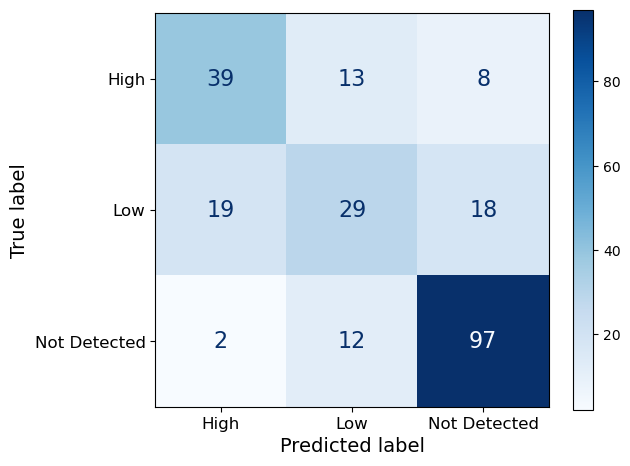

In [126]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    classification_report,
)

auc_class_order = [0, 1, 2]
display_class_order = [2, 1, 0]
display_class_names = ["High", "Low", "Not Detected"]

accuracy = accuracy_score(y_true, y_pred)
balanced_acc = balanced_accuracy_score(y_true, y_pred)
precision_macro = precision_score(
    y_true, y_pred, labels=auc_class_order,
    average="macro", zero_division=0
)
recall_macro = recall_score(
    y_true, y_pred, labels=auc_class_order,
    average="macro", zero_division=0
)
f1_macro = f1_score(
    y_true, y_pred, labels=auc_class_order,
    average="macro", zero_division=0
)
precision_weighted = precision_score(
    y_true, y_pred, labels=auc_class_order,
    average="weighted", zero_division=0
)
recall_weighted = recall_score(
    y_true, y_pred, labels=auc_class_order,
    average="weighted", zero_division=0
)
f1_weighted = f1_score(
    y_true, y_pred, labels=auc_class_order,
    average="weighted", zero_division=0
)
mcc = matthews_corrcoef(y_true, y_pred)

auc_macro_ovr = roc_auc_score(
    y_true, y_proba, labels=auc_class_order,
    multi_class="ovr", average="macro"
)
auc_weighted_ovr = roc_auc_score(
    y_true, y_proba, labels=auc_class_order,
    multi_class="ovr", average="weighted"
)

kappa_linear = cohen_kappa_score(
    y_true, y_pred, labels=auc_class_order, weights="linear"
)
kappa_quadratic = cohen_kappa_score(
    y_true, y_pred, labels=auc_class_order, weights="quadratic"
)
ordinal_mae = np.mean(np.abs(y_true - y_pred))
severe_error_rate = np.mean(np.abs(y_true - y_pred) == 2)

print(f"LOOCV Accuracy:             {accuracy:.4f}")
print(f"Balanced Accuracy:          {balanced_acc:.4f}")
print(f"Macro Precision:            {precision_macro:.4f}")
print(f"Macro Recall:               {recall_macro:.4f}")
print(f"Macro F1 Score:             {f1_macro:.4f}")
print(f"Weighted Precision:         {precision_weighted:.4f}")
print(f"Weighted Recall:            {recall_weighted:.4f}")
print(f"Weighted F1 Score:          {f1_weighted:.4f}")
print(f"MCC:                        {mcc:.4f}")
print(f"Macro OvR ROC-AUC:          {auc_macro_ovr:.4f}")
print(f"Weighted OvR ROC-AUC:       {auc_weighted_ovr:.4f}")
print(f"Linear weighted kappa:      {kappa_linear:.4f}")
print(f"Quadratic weighted kappa:   {kappa_quadratic:.4f}")
print(f"Ordinal MAE:                {ordinal_mae:.4f}")
print(f"Severe error rate:          {severe_error_rate:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=display_class_order,
        target_names=display_class_names,
        digits=4,
        zero_division=0,
    )
)

cm = confusion_matrix(
    y_true, y_pred, labels=display_class_order
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_class_names,
)
disp.plot(
    cmap="Blues",
    values_format="d",
    text_kw={"fontsize": 16},
)
disp.ax_.set_xlabel("Predicted label", fontsize=14)
disp.ax_.set_ylabel("True label", fontsize=14)
disp.ax_.tick_params(axis="x", labelsize=12)
disp.ax_.tick_params(axis="y", labelsize=12)
plt.tight_layout()
plt.show()


In [91]:
import numpy as np

# =============================
# 特徴量・ターゲット
# =============================
X_train = morgan_fps_data_df.to_numpy(dtype=np.float32)
y_train = np.asarray(df_data2).ravel().astype(int)
z_train = df_data3

X_test_2 = morgan_fps_test_df.to_numpy(dtype=np.float32)
y_test_2 = np.asarray(df_test2).ravel().astype(int)
z_test_2 = df_test3

# =============================
# 全学習データで最終Ordinalモデルを学習
# =============================
base_model = OrdinalLightGBM(**best_params)
base_model.fit(X_train, y_train)

if USE_PAVA:
    model = PAVACalibratedOrdinalModel(base_model, pava_calibrator)
else:
    model = base_model

# =============================
# 外部テスト予測
# =============================
y_pred_2 = model.predict(X_test_2)
y_proba_2 = model.predict_proba(X_test_2)
y_cumulative_proba_2 = model.predict_cumulative_proba(X_test_2)

print("Model classes:", model.classes_)
print("Prediction shape:", y_pred_2.shape)
print("Class probability shape:", y_proba_2.shape)
print("Cumulative probability shape:", y_cumulative_proba_2.shape)
print("Probability row sums:", y_proba_2.sum(axis=1)[:5])


Model classes: [0 1 2]
Prediction shape: (52,)
Class probability shape: (52, 3)
Cumulative probability shape: (52, 2)
Probability row sums: [1. 1. 1. 1. 1.]


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

model.classes_: [0 1 2]
y_proba_2 shape: (52, 3)
Test Accuracy:             0.7692
Balanced Accuracy:         0.6747
Macro Precision:           0.7049
Macro Recall:              0.6747
Macro F1 Score:            0.6832
Weighted Precision:        0.7774
Weighted Recall:           0.7692
Weighted F1 Score:         0.7690
MCC:                       0.5984
Macro OvR ROC-AUC:         0.8410
Weighted OvR ROC-AUC:      0.8767
Linear weighted kappa: 0.7062
Quadratic weighted kappa: 0.8101

Classification report:
              precision    recall  f1-score   support

        High     0.7500    0.5455    0.6316        11
         Low     0.4615    0.5455    0.5000        11
Not Detected     0.9032    0.9333    0.9180        30

    accuracy                         0.7692        52
   macro avg     0.7049    0.6747    0.6832        52
weighted avg     0.7774    0.7692    0.7690        52



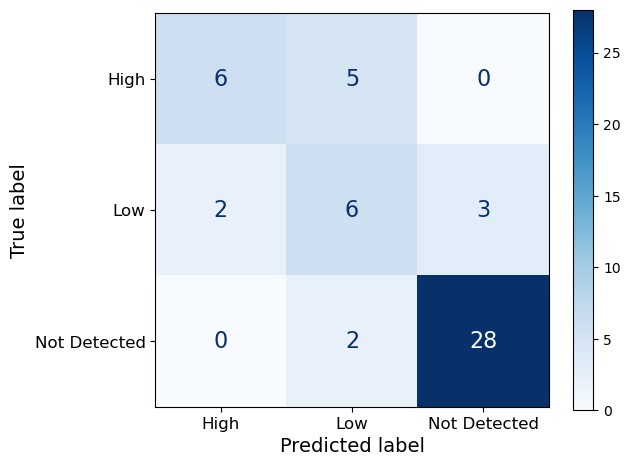

In [127]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
)

# =============================
# 配列形式を統一
# =============================
y_test_2 = np.asarray(y_test_2).ravel()
y_pred_2 = np.asarray(y_pred_2).ravel()
y_proba_2 = np.asarray(y_proba_2)

# クラス定義
# 0 = Low, 1 = Middle, 2 = High
auc_class_order = [0, 1, 2]

# 混同行列・レポートでは High → Middle → Low の順に表示
display_class_order = [2, 1, 0]
display_class_names = ["High", "Low", "Not Detected"]


# =============================
# 基本指標
# =============================
accuracy = accuracy_score(
    y_test_2,
    y_pred_2,
)

balanced_acc = balanced_accuracy_score(
    y_test_2,
    y_pred_2,
)

precision_macro = precision_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="macro",
    zero_division=0,
)

recall_macro = recall_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="macro",
    zero_division=0,
)

f1_macro = f1_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="macro",
    zero_division=0,
)

precision_weighted = precision_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="weighted",
    zero_division=0,
)

recall_weighted = recall_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="weighted",
    zero_division=0,
)

f1_weighted = f1_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="weighted",
    zero_division=0,
)

# MCCは多クラス分類にも対応
mcc = matthews_corrcoef(
    y_test_2,
    y_pred_2,
)


# =============================
# 多クラスROC-AUC
# =============================
# y_proba_2 の列順が model.classes_ = [0, 1, 2] であることを確認
print("model.classes_:", model.classes_)
print("y_proba_2 shape:", y_proba_2.shape)

auc_macro_ovr = roc_auc_score(
    y_test_2,
    y_proba_2,
    labels=auc_class_order,
    multi_class="ovr",
    average="macro",
)

auc_weighted_ovr = roc_auc_score(
    y_test_2,
    y_proba_2,
    labels=auc_class_order,
    multi_class="ovr",
    average="weighted",
)


# =============================
# 結果表示
# =============================
print(f"Test Accuracy:             {accuracy:.4f}")
print(f"Balanced Accuracy:         {balanced_acc:.4f}")
print(f"Macro Precision:           {precision_macro:.4f}")
print(f"Macro Recall:              {recall_macro:.4f}")
print(f"Macro F1 Score:            {f1_macro:.4f}")
print(f"Weighted Precision:        {precision_weighted:.4f}")
print(f"Weighted Recall:           {recall_weighted:.4f}")
print(f"Weighted F1 Score:         {f1_weighted:.4f}")
print(f"MCC:                       {mcc:.4f}")
print(f"Macro OvR ROC-AUC:         {auc_macro_ovr:.4f}")
print(f"Weighted OvR ROC-AUC:      {auc_weighted_ovr:.4f}")

from sklearn.metrics import cohen_kappa_score

kappa_quadratic = cohen_kappa_score(
    y_test_2,
    y_pred_2,
    weights="quadratic"
)

kappa_linear = cohen_kappa_score(
    y_test_2,
    y_pred_2,
    weights="linear"
)

print(f"Linear weighted kappa: {kappa_linear:.4f}")
print(f"Quadratic weighted kappa: {kappa_quadratic:.4f}")

# =============================
# クラス別評価
# =============================
print("\nClassification report:")

print(
    classification_report(
        y_test_2,
        y_pred_2,
        labels=display_class_order,
        target_names=display_class_names,
        digits=4,
        zero_division=0,
    )
)


# =============================
# 混同行列
# =============================
cm = confusion_matrix(
    y_test_2,
    y_pred_2,
    labels=display_class_order,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_class_names,
)

disp.plot(
    cmap="Blues",
    values_format="d",
    text_kw={"fontsize": 16},
)

disp.ax_.set_xlabel(
    "Predicted label",
    fontsize=14,
)

disp.ax_.set_ylabel(
    "True label",
    fontsize=14,
)

disp.ax_.tick_params(
    axis="x",
    labelsize=12,
)

disp.ax_.tick_params(
    axis="y",
    labelsize=12,
)

plt.tight_layout()
plt.show()

## データ保存部分

In [137]:
from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


def calculate_classification_metrics(y_true, y_pred):
    """
    多クラス分類用の評価指標を計算する。

    クラス定義:
        0 = Low
        1 = Middle
        2 = High
    """

    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    class_labels = [0, 1, 2]
    class_names = {
        0: "Not Detected",
        1: "Low",
        2: "High",
    }

    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred,
        ),

        # 各クラスを同じ重みで平均
        "precision_macro": precision_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0,
        ),
        "recall_macro": recall_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0,
        ),
        "f1_macro": f1_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0,
        ),

        # クラスのサンプル数で重み付け
        "precision_weighted": precision_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="weighted",
            zero_division=0,
        ),
        "recall_weighted": recall_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="weighted",
            zero_division=0,
        ),
        "f1_weighted": f1_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="weighted",
            zero_division=0,
        ),

        # 多クラス対応MCC
        "mcc": matthews_corrcoef(
            y_true,
            y_pred,
        ),

        # 順序付きクラス向け
        "linear_weighted_kappa": cohen_kappa_score(
            y_true,
            y_pred,
            labels=class_labels,
            weights="linear",
        ),
        "quadratic_weighted_kappa": cohen_kappa_score(
            y_true,
            y_pred,
            labels=class_labels,
            weights="quadratic",
        ),

        # Low=0, Middle=1, High=2として評価
        "ordinal_mae": np.mean(
            np.abs(y_true - y_pred)
        ),
        "within_one_class_accuracy": np.mean(
            np.abs(y_true - y_pred) <= 1
        ),
    }

    # クラス別指標
    precision_each = precision_score(
        y_true,
        y_pred,
        labels=class_labels,
        average=None,
        zero_division=0,
    )

    recall_each = recall_score(
        y_true,
        y_pred,
        labels=class_labels,
        average=None,
        zero_division=0,
    )

    f1_each = f1_score(
        y_true,
        y_pred,
        labels=class_labels,
        average=None,
        zero_division=0,
    )

    for index, class_label in enumerate(class_labels):
        class_name = class_names[class_label]

        metrics[f"precision_{class_name}"] = precision_each[index]
        metrics[f"recall_{class_name}"] = recall_each[index]
        metrics[f"f1_{class_name}"] = f1_each[index]

    # JSON保存できるようPythonのfloatへ変換
    metrics = {
        key: float(value)
        for key, value in metrics.items()
    }

    return metrics

In [142]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
)


def plot_and_save_confusion_matrix(
    y_true,
    y_pred,
    class_order=(2, 1, 0),
    class_names=("High", "Low", "Not Detected"),
    save_path=None,
    show=False,
):
    """
    多クラス分類用の混同行列を作成・保存する。

    クラス定義
    ----------
    0 : Low
    1 : Middle
    2 : High

    表示順
    ------
    High -> Middle -> Low
    """

    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    if len(class_order) != len(class_names):
        raise ValueError(
            "class_orderとclass_namesの要素数が一致していません。"
        )

    # labels引数で表示順を直接指定するため、
    # 後から行列を並べ替える必要はない
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(class_order),
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=list(class_names),
    )

    disp.plot(
        cmap="Greys",
        values_format="d",
        text_kw={"fontsize": 16},
    )

    disp.ax_.set_xlabel(
        "Predicted label",
        fontsize=14,
    )

    disp.ax_.set_ylabel(
        "True label",
        fontsize=14,
    )

    disp.ax_.tick_params(
        axis="x",
        labelsize=12,
    )

    disp.ax_.tick_params(
        axis="y",
        labelsize=12,
    )

    plt.tight_layout()

    if save_path is not None:
        save_path = str(save_path)

        plt.savefig(
            save_path,
            format="svg",
            bbox_inches="tight",
            dpi=300,
        )

    if show:
        plt.show()
    else:
        plt.close()

    return cm

In [139]:
def _json_converter(obj):
    """
    NumPy型やPathをJSON保存可能な型に変換する。
    """

    if isinstance(obj, np.integer):
        return int(obj)

    if isinstance(obj, np.floating):
        return float(obj)

    if isinstance(obj, np.ndarray):
        return obj.tolist()

    if isinstance(obj, Path):
        return str(obj)

    raise TypeError(
        f"Object of type {type(obj).__name__} "
        "is not JSON serializable"
    )

In [140]:
from pathlib import Path
import json
import joblib
import numpy as np

from sklearn.metrics import confusion_matrix


def save_model_params_metrics_features_and_figures(
    model,
    model_params,
    feature_params,
    save_dir,
    model_name="model",
    y_true_loocv=None,
    y_pred_loocv=None,
    y_true_test=None,
    y_pred_test=None,
    class_order=(2, 1, 0),
    class_names=("High", "Low", "Not Detected"),
):
    """
    学習済みモデル、モデル条件、特徴量条件、評価指標、
    混同行列図をまとめて保存する。

    クラス定義
    ----------
    0 : Not Detected
    1 : Low
    2 : High

    Parameters
    ----------
    model:
        学習済みモデル。

    model_params : dict
        モデルのハイパーパラメータ。

    feature_params : dict
        特徴量作成条件。

    save_dir : str or Path
        保存先フォルダ。

    model_name : str
        保存ファイル名のベース。

    y_true_loocv, y_pred_loocv:
        LOOCVの正解ラベルと予測ラベル。

    y_true_test, y_pred_test:
        外部テストの正解ラベルと予測ラベル。

    class_order:
        混同行列の表示順。
        デフォルトは High → Middle → Low。

    class_names:
        class_orderに対応する表示名。
    """

    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    class_order = list(class_order)
    class_names = list(class_names)

    if len(class_order) != len(class_names):
        raise ValueError(
            "class_orderとclass_namesの要素数が一致していません。"
        )

    # =============================
    # model保存
    # =============================
    model_path = save_dir / f"{model_name}.pkl"
    joblib.dump(model, model_path)

    # =============================
    # モデルハイパーパラメータ保存
    # =============================
    model_params_path = (
        save_dir / f"{model_name}_model_params.json"
    )

    with open(
        model_params_path,
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            model_params,
            f,
            indent=4,
            ensure_ascii=False,
            default=_json_converter,
        )

    # =============================
    # 特徴量作成条件保存
    # =============================
    feature_params_path = (
        save_dir / f"{model_name}_feature_params.json"
    )

    with open(
        feature_params_path,
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            feature_params,
            f,
            indent=4,
            ensure_ascii=False,
            default=_json_converter,
        )

    # =============================
    # 評価指標
    # =============================
    all_metrics = {}

    # -----------------------------
    # LOOCV
    # -----------------------------
    if (
        y_true_loocv is not None
        and y_pred_loocv is not None
    ):
        y_true_loocv = np.asarray(
            y_true_loocv
        ).ravel()

        y_pred_loocv = np.asarray(
            y_pred_loocv
        ).ravel()

        loocv_metrics = (
            calculate_classification_metrics(
                y_true_loocv,
                y_pred_loocv,
            )
        )

        cm_loocv = confusion_matrix(
            y_true_loocv,
            y_pred_loocv,
            labels=class_order,
        )

        loocv_metrics[
            "confusion_matrix"
        ] = cm_loocv.tolist()

        loocv_metrics[
            "confusion_matrix_class_order"
        ] = class_order

        loocv_metrics[
            "confusion_matrix_class_names"
        ] = class_names

        all_metrics["LOOCV"] = loocv_metrics

        plot_and_save_confusion_matrix(
            y_true=y_true_loocv,
            y_pred=y_pred_loocv,
            class_order=class_order,
            class_names=class_names,
            save_path=(
                save_dir
                / "LOOCV_confusion_matrix.svg"
            ),
            show=False,
        )

    # -----------------------------
    # 外部テスト
    # -----------------------------
    if (
        y_true_test is not None
        and y_pred_test is not None
    ):
        y_true_test = np.asarray(
            y_true_test
        ).ravel()

        y_pred_test = np.asarray(
            y_pred_test
        ).ravel()

        test_metrics = (
            calculate_classification_metrics(
                y_true_test,
                y_pred_test,
            )
        )

        cm_test = confusion_matrix(
            y_true_test,
            y_pred_test,
            labels=class_order,
        )

        test_metrics[
            "confusion_matrix"
        ] = cm_test.tolist()

        test_metrics[
            "confusion_matrix_class_order"
        ] = class_order

        test_metrics[
            "confusion_matrix_class_names"
        ] = class_names

        all_metrics["Test"] = test_metrics

        plot_and_save_confusion_matrix(
            y_true=y_true_test,
            y_pred=y_pred_test,
            class_order=class_order,
            class_names=class_names,
            save_path=(
                save_dir
                / "test_confusion_matrix.svg"
            ),
            show=False,
        )

    # =============================
    # 評価指標保存
    # =============================
    metrics_path = (
        save_dir / f"{model_name}_metrics.json"
    )

    with open(
        metrics_path,
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            all_metrics,
            f,
            indent=4,
            ensure_ascii=False,
            default=_json_converter,
        )

    # =============================
    # 保存結果表示
    # =============================
    print(f"Model saved: {model_path}")
    print(
        f"Model params saved: "
        f"{model_params_path}"
    )
    print(
        f"Feature params saved: "
        f"{feature_params_path}"
    )
    print(f"Metrics saved: {metrics_path}")

    if (
        y_true_loocv is not None
        and y_pred_loocv is not None
    ):
        print(
            "LOOCV confusion matrix saved: "
            f"{save_dir / 'LOOCV_confusion_matrix.svg'}"
        )

    if (
        y_true_test is not None
        and y_pred_test is not None
    ):
        print(
            "Test confusion matrix saved: "
            f"{save_dir / 'test_confusion_matrix.svg'}"
        )

    return {
        "model_path": model_path,
        "model_params_path": model_params_path,
        "feature_params_path": feature_params_path,
        "metrics_path": metrics_path,
        "metrics": all_metrics,
    }

In [143]:
best_model = model

model_params_to_save = best_params.copy()
model_params_to_save.update({
    "model_type": "Cumulative binary Ordinal LightGBM",
    "class_definition": {
        "0": "Not Detected",
        "1": "Low",
        "2": "High",
    },
    "binary_problem_1": "y > 0: Not Detected vs Low+High",
    "binary_problem_2": "y > 1: Not Detected+Low vs High",
    "optuna_objective": "quadratic_weighted_kappa",
    "cv_n_splits": n_splits,
    "use_pava": USE_PAVA,
    "probability_calibration": (
        "PAVA (isotonic regression)" if USE_PAVA else "None"
    ),
    "calibration_data": (
        "LOOCV out-of-fold predictions" if USE_PAVA else None
    ),
})

feature_params = {
    "fingerprint_type": "Sort&Slice Morgan fingerprint",
    "radius": radius,
    "L": L,
    "use_counts": use_counts,
    "min_df": min_df,
    "max_df_ratio": max_df_ratio,
    "n_selected_raw_ids": len(selected_raw_ids),
}

save_dir = Path("../output/multi_classification/double_model_run_003_test")
file_tag = "PAVA" if USE_PAVA else "RAW"

save_model_params_metrics_features_and_figures(
    model=best_model,
    model_params=model_params_to_save,
    feature_params=feature_params,
    save_dir=save_dir,
    model_name=f"best_ordinal_lgbm_{file_tag.lower()}",
    y_true_loocv=y_true,
    y_pred_loocv=y_pred,
    y_true_test=y_test_2,
    y_pred_test=y_pred_2,
)


Model saved: ../output/multi_classification/double_model_run_003_test/best_ordinal_lgbm_pava.pkl
Model params saved: ../output/multi_classification/double_model_run_003_test/best_ordinal_lgbm_pava_model_params.json
Feature params saved: ../output/multi_classification/double_model_run_003_test/best_ordinal_lgbm_pava_feature_params.json
Metrics saved: ../output/multi_classification/double_model_run_003_test/best_ordinal_lgbm_pava_metrics.json
LOOCV confusion matrix saved: ../output/multi_classification/double_model_run_003_test/LOOCV_confusion_matrix.svg
Test confusion matrix saved: ../output/multi_classification/double_model_run_003_test/test_confusion_matrix.svg


{'model_path': PosixPath('../output/multi_classification/double_model_run_003_test/best_ordinal_lgbm_pava.pkl'),
 'model_params_path': PosixPath('../output/multi_classification/double_model_run_003_test/best_ordinal_lgbm_pava_model_params.json'),
 'feature_params_path': PosixPath('../output/multi_classification/double_model_run_003_test/best_ordinal_lgbm_pava_feature_params.json'),
 'metrics_path': PosixPath('../output/multi_classification/double_model_run_003_test/best_ordinal_lgbm_pava_metrics.json'),
 'metrics': {'LOOCV': {'accuracy': 0.6962025316455697,
   'balanced_accuracy': 0.6544226044226044,
   'precision_macro': 0.6585516410719663,
   'recall_macro': 0.6544226044226044,
   'f1_macro': 0.6541310541310542,
   'precision_weighted': 0.6834642608029456,
   'recall_weighted': 0.6962025316455697,
   'f1_weighted': 0.6874499621335064,
   'mcc': 0.5195254527980309,
   'linear_weighted_kappa': 0.6065354713313897,
   'quadratic_weighted_kappa': 0.6879646840148699,
   'ordinal_mae': 0.34

## 予測データの保存

In [98]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import LeaveOneOut


def evaluate_ordinal_loocv_and_save(
    X,
    y,
    compound_info,
    model_params,
    save_path,
    use_pava=True,
):
    """
    Ordinal LightGBMをLOOCVで評価し、
    化合物情報・正解・予測・各クラス確率をCSV保存する。

    ラベル:
        0 = Low
        1 = Middle
        2 = High
    """

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y).ravel().astype(int)

    compound_info = pd.DataFrame(compound_info).reset_index(drop=True)

    if len(X) != len(y):
        raise ValueError(
            f"Xとyの行数が一致しません: X={len(X)}, y={len(y)}"
        )

    if len(compound_info) != len(y):
        raise ValueError(
            "compound_infoとyの行数が一致しません: "
            f"compound_info={len(compound_info)}, y={len(y)}"
        )

    n_samples = len(y)

    # PAVAの学習には、各サンプルを学習に使っていないOOF累積確率を使う。
    raw_cumulative_proba = np.zeros((n_samples, 2), dtype=float)

    loo = LeaveOneOut()

    for train_idx, valid_idx in loo.split(X):
        model = OrdinalLightGBM(**model_params)

        model.fit(
            X[train_idx],
            y[train_idx],
        )

        raw_cumulative_proba[valid_idx] = (
            model.predict_cumulative_proba(X[valid_idx])
        )

    if use_pava:
        pava_calibrator = OrdinalPAVACalibrator().fit(
            raw_cumulative_proba, y
        )
        y_proba = pava_calibrator.predict_proba(raw_cumulative_proba)
    else:
        pava_calibrator = None
        q1 = raw_cumulative_proba[:, 0]
        q2 = raw_cumulative_proba[:, 1]
        y_proba = np.column_stack([1.0 - q1, q1 - q2, q2])
        y_proba = np.clip(y_proba, 0.0, 1.0)
        y_proba /= y_proba.sum(axis=1, keepdims=True)
    y_pred = np.argmax(y_proba, axis=1)

    label_map = {
        0: "Low",
        1: "Middle",
        2: "High",
    }

    prediction_df = compound_info.copy()

    # 元の行番号
    prediction_df.insert(
        0,
        "sample_index",
        np.arange(n_samples),
    )

    prediction_df["true_class"] = y
    prediction_df["true_label"] = pd.Series(y).map(label_map)

    prediction_df["predicted_class"] = y_pred
    prediction_df["predicted_label"] = pd.Series(y_pred).map(label_map)

    prediction_df["raw_probability_above_low"] = raw_cumulative_proba[:, 0]
    prediction_df["raw_probability_high"] = raw_cumulative_proba[:, 1]
    prediction_df["probability_low"] = y_proba[:, 0]
    prediction_df["probability_middle"] = y_proba[:, 1]
    prediction_df["probability_high"] = y_proba[:, 2]

    # 予測確信度
    prediction_df["maximum_probability"] = np.max(
        y_proba,
        axis=1,
    )

    # 正誤
    prediction_df["correct"] = y == y_pred

    # 順序分類として何段階外したか
    prediction_df["ordinal_error"] = np.abs(y - y_pred)

    # 重大誤分類：LowとHighの直接取り違え
    prediction_df["severe_error"] = (
        np.abs(y - y_pred) == 2
    )

    save_path = Path(save_path)
    save_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    prediction_df.to_csv(
        save_path,
        index=False,
        encoding="utf-8-sig",
    )

    print(f"LOOCV predictions saved: {save_path}")

    return prediction_df, y_pred, y_proba, pava_calibrator

In [99]:
def predict_dataset_and_save(
    model,
    X,
    y,
    compound_info,
    save_path,
    dataset_name,
):
    """
    学習済みOrdinalモデルでデータを予測し、
    化合物情報付きCSVとして保存する。
    """

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y).ravel().astype(int)

    compound_info = pd.DataFrame(
        compound_info
    ).reset_index(drop=True)

    if len(X) != len(y):
        raise ValueError(
            f"Xとyの行数が一致しません: X={len(X)}, y={len(y)}"
        )

    if len(compound_info) != len(y):
        raise ValueError(
            "compound_infoとyの行数が一致しません: "
            f"compound_info={len(compound_info)}, y={len(y)}"
        )

    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)

    label_map = {
        0: "Low",
        1: "Middle",
        2: "High",
    }

    prediction_df = compound_info.copy()

    prediction_df.insert(
        0,
        "sample_index",
        np.arange(len(y)),
    )

    prediction_df.insert(
        1,
        "dataset",
        dataset_name,
    )

    prediction_df["true_class"] = y
    prediction_df["true_label"] = pd.Series(y).map(label_map)

    prediction_df["predicted_class"] = y_pred
    prediction_df["predicted_label"] = pd.Series(y_pred).map(label_map)

    prediction_df["probability_low"] = y_proba[:, 0]
    prediction_df["probability_middle"] = y_proba[:, 1]
    prediction_df["probability_high"] = y_proba[:, 2]

    prediction_df["maximum_probability"] = np.max(
        y_proba,
        axis=1,
    )

    prediction_df["correct"] = y == y_pred
    prediction_df["ordinal_error"] = np.abs(y - y_pred)
    prediction_df["severe_error"] = (
        np.abs(y - y_pred) == 2
    )

    save_path = Path(save_path)
    save_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    prediction_df.to_csv(
        save_path,
        index=False,
        encoding="utf-8-sig",
    )

    print(f"{dataset_name} predictions saved: {save_path}")

    return prediction_df, y_pred, y_proba


def save_existing_predictions(
    y_true,
    y_pred,
    y_proba,
    cumulative_proba,
    compound_info,
    save_path,
    dataset_name,
):
    """前半で計算済みの予測を再予測せず、そのままCSV保存する。"""
    y_true = np.asarray(y_true).ravel().astype(int)
    y_pred = np.asarray(y_pred).ravel().astype(int)
    y_proba = np.asarray(y_proba, dtype=float)
    cumulative_proba = np.asarray(cumulative_proba, dtype=float)
    compound_info = pd.DataFrame(compound_info).reset_index(drop=True)

    n_samples = len(y_true)
    if not (
        len(y_pred) == n_samples
        and y_proba.shape == (n_samples, 3)
        and cumulative_proba.shape == (n_samples, 2)
        and len(compound_info) == n_samples
    ):
        raise ValueError("保存対象の予測配列と化合物情報の形状が一致しません。")

    label_map = {0: "Low", 1: "Middle", 2: "High"}
    prediction_df = compound_info.copy()
    prediction_df.insert(0, "sample_index", np.arange(n_samples))
    prediction_df.insert(1, "dataset", dataset_name)
    prediction_df["pava_applied"] = USE_PAVA
    prediction_df["true_class"] = y_true
    prediction_df["true_label"] = pd.Series(y_true).map(label_map)
    prediction_df["predicted_class"] = y_pred
    prediction_df["predicted_label"] = pd.Series(y_pred).map(label_map)
    prediction_df["probability_low"] = y_proba[:, 0]
    prediction_df["probability_middle"] = y_proba[:, 1]
    prediction_df["probability_high"] = y_proba[:, 2]
    prediction_df["probability_above_low"] = cumulative_proba[:, 0]
    prediction_df["probability_high_cumulative"] = cumulative_proba[:, 1]
    prediction_df["maximum_probability"] = np.max(y_proba, axis=1)
    prediction_df["correct"] = y_true == y_pred
    prediction_df["ordinal_error"] = np.abs(y_true - y_pred)
    prediction_df["severe_error"] = np.abs(y_true - y_pred) == 2

    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    prediction_df.to_csv(save_path, index=False, encoding="utf-8-sig")
    print(f"Existing {dataset_name} predictions saved: {save_path}")
    return prediction_df

In [100]:
# 前半のLOOCVで評価に使用した予測を、そのまま保存する。
loocv_prediction_df = save_existing_predictions(
    y_true=y_true,
    y_pred=y_pred,
    y_proba=y_proba,
    cumulative_proba=y_cumulative_proba,
    compound_info=df_data3,
    save_path=(
        save_dir / f"Ordinal_LightGBM_{file_tag}_LOOCV_predictions.csv"
    ),
    dataset_name="LOOCV",
)

# 前半の外部テスト評価に使用した予測を、そのまま保存する。
test_prediction_df = save_existing_predictions(
    y_true=y_test_2,
    y_pred=y_pred_2,
    y_proba=y_proba_2,
    cumulative_proba=y_cumulative_proba_2,
    compound_info=df_test3,
    save_path=(
        save_dir / f"Ordinal_LightGBM_{file_tag}_test_predictions.csv"
    ),
    dataset_name="Test",
)

Existing LOOCV predictions saved: ../output/multi_classification/double_model_run_003_PAVA/Ordinal_LightGBM_PAVA_LOOCV_predictions.csv
Existing Test predictions saved: ../output/multi_classification/double_model_run_003_PAVA/Ordinal_LightGBM_PAVA_test_predictions.csv


# SHAP解析

In [101]:
import matplotlib.pyplot as plt
import numpy as np
import shap


def extract_positive_class_shap(shap_result):
    """SHAPのバージョン差を吸収して二値分類の陽性クラスを返す。"""
    values = shap_result.values if hasattr(shap_result, "values") else shap_result
    if isinstance(values, list):
        return np.asarray(values[1], dtype=float)

    values = np.asarray(values, dtype=float)
    if values.ndim == 2:
        return values
    if values.ndim == 3 and values.shape[-1] == 2:
        return values[:, :, 1]
    if values.ndim == 3 and values.shape[0] == 2:
        return values[1]
    raise ValueError(f"想定外のSHAP値のshapeです: {values.shape}")


# PAVAは確率に対する後処理なので、SHAPは補正前の2つの木モデルへ適用する。
ordinal_tree_models = {
    "above_low": base_model.model_above_low_,  # Middle/High方向
    "high": base_model.model_high_,            # High方向
}
X_shap = np.asarray(X_test_2, dtype=np.float32)
feature_names = list(morgan_fps_test_df.columns)
if len(feature_names) != X_shap.shape[1]:
    feature_names = [f"FP_{i}" for i in range(X_shap.shape[1])]

shap_values_by_target = {}
shap_explainers = {}
for target_name, tree_model in ordinal_tree_models.items():
    explainer = shap.TreeExplainer(tree_model)
    shap_result = explainer.shap_values(X_shap)
    target_shap = extract_positive_class_shap(shap_result)
    shap_explainers[target_name] = explainer
    shap_values_by_target[target_name] = target_shap

    shap.summary_plot(
        target_shap, X_shap, feature_names=feature_names,
        plot_type="dot", show=False,
    )
    summary_path = save_dir / f"SHAP_summary_{target_name}.svg"
    plt.savefig(summary_path, format="svg", bbox_inches="tight", dpi=300)
    plt.close()
    print(f"SHAP summary saved: {summary_path}")

print("above_low: 正のSHAP値ほど Middle/High 方向")
print("high: 正のSHAP値ほど High 方向")

/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


SHAP summary saved: ../output/multi_classification/double_model_run_003_PAVA/SHAP_summary_above_low.svg
SHAP summary saved: ../output/multi_classification/double_model_run_003_PAVA/SHAP_summary_high.svg
above_low: 正のSHAP値ほど Middle/High 方向
high: 正のSHAP値ほど High 方向


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [148]:
import matplotlib.pyplot as plt
import numpy as np
import shap


def extract_positive_class_shap(shap_result):
    """SHAPのバージョン差を吸収して二値分類の陽性クラスを返す。"""

    values = (
        shap_result.values
        if hasattr(shap_result, "values")
        else shap_result
    )

    if isinstance(values, list):
        return np.asarray(
            values[1],
            dtype=float,
        )

    values = np.asarray(
        values,
        dtype=float,
    )

    if values.ndim == 2:
        return values

    if values.ndim == 3 and values.shape[-1] == 2:
        return values[:, :, 1]

    if values.ndim == 3 and values.shape[0] == 2:
        return values[1]

    raise ValueError(
        f"想定外のSHAP値のshapeです: {values.shape}"
    )


# PAVAは確率に対する後処理なので、
# SHAPは補正前の2つの木モデルへ適用する
ordinal_tree_models = {
    "above_low": base_model.model_above_low_,
    "high": base_model.model_high_,
}


X_shap = np.asarray(
    X_test_2,
    dtype=np.float32,
)


feature_names = list(
    morgan_fps_test_df.columns
)


if len(feature_names) != X_shap.shape[1]:
    feature_names = [
        f"FP_{i}"
        for i in range(X_shap.shape[1])
    ]


shap_values_by_target = {}
shap_explainers = {}


for target_name, tree_model in ordinal_tree_models.items():

    explainer = shap.TreeExplainer(
        tree_model
    )

    shap_result = explainer.shap_values(
        X_shap
    )

    target_shap = extract_positive_class_shap(
        shap_result
    )

    shap_explainers[
        target_name
    ] = explainer

    shap_values_by_target[
        target_name
    ] = target_shap

    # =========================================================
    # SHAP横棒グラフ
    # =========================================================

    shap.summary_plot(
        target_shap,
        X_shap,
        feature_names=feature_names,
        plot_type="bar",
        max_display=5,
        show=False,
    )

    # 棒をモノクロ化
    ax = plt.gca()

    for patch in ax.patches:
        patch.set_facecolor("black")
        patch.set_edgecolor("black")

    summary_path = (
        save_dir
        / f"SHAP_bar_{target_name}.svg"
    )

    plt.savefig(
        summary_path,
        format="svg",
        bbox_inches="tight",
        dpi=300,
    )

    plt.close()

    print(
            f"SHAP bar plot saved: {summary_path}"
        )


print(
    "above_low: 正のSHAP値ほど Middle/High 方向"
)

print(
    "high: 正のSHAP値ほど High 方向"
)

SHAP bar plot saved: ../output/multi_classification/double_model_run_003_test/SHAP_bar_above_low.svg
SHAP bar plot saved: ../output/multi_classification/double_model_run_003_test/SHAP_bar_high.svg
above_low: 正のSHAP値ほど Middle/High 方向
high: 正のSHAP値ほど High 方向


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [102]:
from pathlib import Path

from IPython.display import SVG, display
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D


def _shap_color(value):
    """正の寄与を赤、負の寄与を青、0を薄い灰色にする。"""
    value = float(np.clip(value, -1.0, 1.0))
    if value > 0:
        return (1.0, 1.0 - value, 1.0 - value)
    if value < 0:
        return (1.0 + value, 1.0 + value, 1.0)
    return (0.92, 0.92, 0.92)


def project_shap_to_molecule(
    compound_index,
    shap_values,
    molecules,
    bitinfo_list,
    compound_info,
    output=None,
    raw_ids=None,
    size=(600, 500),
    show=True,
):
    """保存済みbitInfoを使い、fingerprint SHAP値を原子・結合へ投影する。"""
    if not 0 <= compound_index < len(molecules):
        raise IndexError(f"compound_indexが範囲外です: {compound_index}")

    mol = Chem.Mol(molecules[compound_index])
    bit_info = bitinfo_list[compound_index]
    shap_row = np.asarray(shap_values[compound_index], dtype=float).ravel()
    if raw_ids is not None and len(raw_ids) != len(shap_row):
        raise ValueError("SHAP列数とselected_raw_idsの要素数が一致しません。")

    atom_contributions = np.zeros(mol.GetNumAtoms(), dtype=float)
    for column_index, shap_value in enumerate(shap_row):
        if shap_value == 0:
            continue
        bit_id = column_index if raw_ids is None else raw_ids[column_index]
        occurrences = bit_info.get(bit_id, [])
        if not occurrences:
            continue

        occurrence_share = shap_value / len(occurrences)
        for center_atom, env_radius in occurrences:
            atom_indices = {center_atom}
            if env_radius > 0:
                bond_indices = Chem.FindAtomEnvironmentOfRadiusN(
                    mol, env_radius, center_atom
                )
                for bond_index in bond_indices:
                    bond = mol.GetBondWithIdx(bond_index)
                    atom_indices.update([bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()])
            atom_share = occurrence_share / len(atom_indices)
            for atom_index in atom_indices:
                atom_contributions[atom_index] += atom_share

    max_abs = np.max(np.abs(atom_contributions))
    scaled = atom_contributions / max_abs if max_abs > 0 else atom_contributions
    atom_colors = {i: _shap_color(v) for i, v in enumerate(scaled)}
    bond_colors = {}
    for bond in mol.GetBonds():
        value = (scaled[bond.GetBeginAtomIdx()] + scaled[bond.GetEndAtomIdx()]) / 2.0
        bond_colors[bond.GetIdx()] = _shap_color(value)

    rdDepictor.Compute2DCoords(mol)
    prepared = rdMolDraw2D.PrepareMolForDrawing(mol)
    drawer = rdMolDraw2D.MolDraw2DSVG(*size)
    drawer.drawOptions().useBWAtomPalette()
    drawer.DrawMolecule(
        prepared,
        highlightAtoms=list(atom_colors),
        highlightAtomColors=atom_colors,
        highlightBonds=list(bond_colors),
        highlightBondColors=bond_colors,
    )
    drawer.FinishDrawing()
    svg = drawer.GetDrawingText()

    if output is not None:
        output = Path(output)
        output.parent.mkdir(parents=True, exist_ok=True)
        output.write_text(svg, encoding="utf-8")
        print(f"Molecular SHAP projection saved: {output}")
    if show:
        row = compound_info.reset_index(drop=True).iloc[compound_index]
        name = row.get("name", row.get("Name", f"index={compound_index}"))
        print(f"Compound: {name}")
        display(SVG(svg))
    return atom_contributions, svg

Molecular SHAP projection saved: ../output/multi_classification/double_model_run_003_PAVA/SHAP_above_low_index_41.svg
Compound: index=41


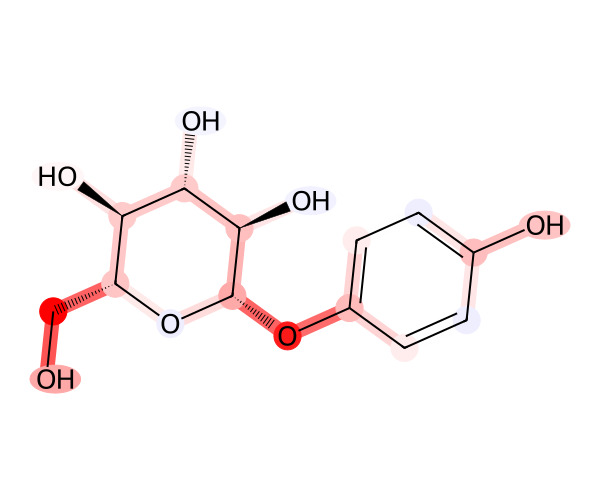

In [113]:
# 投影対象: 'above_low'（Middle/High方向）または 'high'（High方向）
SHAP_TARGET = "above_low"
COMPOUND_INDEX = 41

if SHAP_TARGET not in shap_values_by_target:
    raise ValueError(f"SHAP_TARGETは{list(shap_values_by_target)}から選んでください。")

# 現在のモデルは2048-bit Morgan（FP_i）を使用しているため、
# セル7で保存済みのbitInfo_list_testをそのまま利用する。
atom_contributions, molecule_shap_svg = project_shap_to_molecule(
    compound_index=COMPOUND_INDEX,
    shap_values=shap_values_by_target[SHAP_TARGET],
    molecules=mol_list_test,
    bitinfo_list=bitInfo_list_test,
    compound_info=df_test3,
    output=(
        save_dir / f"SHAP_{SHAP_TARGET}_index_{COMPOUND_INDEX}.svg"
    ),
    raw_ids=None,
    show=True,
)

In [107]:
df_test3

,iso_SMILES,ROMol
0,C1=CC(=CC=C1N)O,<rdkit.Chem.rdchem.Mol object at 0x34274a500>
1,C1=CC(=C(C(=C1)O)O)O,<rdkit.Chem.rdchem.Mol object at 0x34274a180>
2,C1=C(C=C(C(=C1O)O)O)C(=O)O.O,<rdkit.Chem.rdchem.Mol object at 0x34274a340>
3,CC1=CC(=C(C=C1)O)O,<rdkit.Chem.rdchem.Mol object at 0x34274a260>
4,COC1=C(C=CC(=C1)/C=C/C(=O)CC(=O)/C=C/C2=CC(=C(...,<rdkit.Chem.rdchem.Mol object at 0x34274a0a0>
5,COC1=C(C=CC(=C1)/C=C/C(=O)O)O,<rdkit.Chem.rdchem.Mol object at 0x342749fc0>
6,COC1=C(C=C(C=C1)/C=C/C(=O)O)O,<rdkit.Chem.rdchem.Mol object at 0x342749ee0>
7,Oc1c(OC)cc(/C=C/C(O)=O)cc1OC,<rdkit.Chem.rdchem.Mol object at 0x342749e00>
8,C1C(O)=CC=C(/C=C/CO)C=1,<rdkit.Chem.rdchem.Mol object at 0x342749d20>
9,C1=CC(=C(C=C1/C=C/C(=O)O)O)O,<rdkit.Chem.rdchem.Mol object at 0x342749c40>


## FP番号から部分構造を確認

In [117]:
def find_fp_occurrences(fp_number, dataset="both"):
    """既存のbitInfoからFP番号に対応する全出現箇所を検索する。"""
    fp_number = int(fp_number)
    if not 0 <= fp_number < morgan_fps_data_df.shape[1]:
        raise ValueError(
            f"FP番号は0〜{morgan_fps_data_df.shape[1] - 1}で指定してください。"
        )

    sources = {
        "train": (mol_list_train, bitInfo_list_train, df_data3),
        "test": (mol_list_test, bitInfo_list_test, df_test3),
    }
    if dataset == "both":
        selected_sources = sources.items()
    elif dataset in sources:
        selected_sources = [(dataset, sources[dataset])]
    else:
        raise ValueError("datasetは'train'、'test'、'both'から選んでください。")

    records = []
    for dataset_name, (molecules, bitinfos, compound_info) in selected_sources:
        compound_info = compound_info.reset_index(drop=True)
        for molecule_index, (mol, bit_info) in enumerate(zip(molecules, bitinfos)):
            for occurrence_index, (center_atom, env_radius) in enumerate(
                bit_info.get(fp_number, [])
            ):
                if env_radius == 0:
                    substructure = mol.GetAtomWithIdx(center_atom).GetSymbol()
                else:
                    environment = Chem.FindAtomEnvironmentOfRadiusN(
                        mol, env_radius, center_atom
                    )
                    substructure = Chem.MolToSmiles(
                        Chem.PathToSubmol(mol, environment)
                    )
                row = compound_info.iloc[molecule_index]
                compound_name = next(
                    (row[column] for column in ["name", "Name", "ID"]
                     if column in row.index),
                    f"{dataset_name}_{molecule_index}",
                )
                records.append({
                    "dataset": dataset_name,
                    "molecule_index": molecule_index,
                    "occurrence_index": occurrence_index,
                    "compound": compound_name,
                    "center_atom": center_atom,
                    "radius": env_radius,
                    "substructure_smiles": substructure,
                })
    return pd.DataFrame(records)


def visualize_fp_structure(
    fp_number, hit_index=0, dataset="both", output=None,
    size=(450, 350), show=True,
):
    """指定FPのMorgan環境だけを親分子から切り出して描画する。"""
    hits = find_fp_occurrences(fp_number, dataset=dataset)
    if hits.empty:
        raise ValueError(f"FP_{fp_number}を含む分子が見つかりません。")
    if not 0 <= hit_index < len(hits):
        raise IndexError(f"hit_indexは0〜{len(hits) - 1}で指定してください。")

    hit = hits.iloc[hit_index]
    molecules = mol_list_train if hit["dataset"] == "train" else mol_list_test
    mol = Chem.Mol(molecules[int(hit["molecule_index"])])
    center_atom = int(hit["center_atom"])
    env_radius = int(hit["radius"])

    # 親分子全体ではなく、Morgan環境の部分構造だけを作る。
    if env_radius == 0:
        editable = Chem.RWMol()
        editable.AddAtom(Chem.Atom(mol.GetAtomWithIdx(center_atom)))
        submol = editable.GetMol()
    else:
        environment_bonds = list(Chem.FindAtomEnvironmentOfRadiusN(
            mol, env_radius, center_atom
        ))
        submol = Chem.PathToSubmol(mol, environment_bonds)

    rdDepictor.Compute2DCoords(submol)
    prepared = rdMolDraw2D.PrepareMolForDrawing(submol)
    drawer = rdMolDraw2D.MolDraw2DSVG(*size)
    drawer.drawOptions().useBWAtomPalette()
    legend = (
        f"FP_{int(fp_number)} | {hit['dataset']}[{int(hit['molecule_index'])}] "
        f"| radius={env_radius}"
    )
    drawer.DrawMolecule(prepared, legend=legend)
    drawer.FinishDrawing()
    svg = drawer.GetDrawingText()

    if output is not None:
        output = Path(output)
        output.parent.mkdir(parents=True, exist_ok=True)
        output.write_text(svg, encoding="utf-8")
        print(f"FP structure saved: {output}")
    if show:
        display(hits)
        display(SVG(svg))
    return hits, svg

FP structure saved: ../output/multi_classification/double_model_run_003_PAVA/FP_1226_hit_0.svg


,dataset,molecule_index,occurrence_index,compound,center_atom,radius,substructure_smiles
0,train,54,0,train_54,0,3,Cc1ccc(O)cc1
1,train,55,0,train_55,0,3,Cc1ccc(O)cc1
2,train,82,0,train_82,12,3,Cc1ccc(O)cc1
3,train,98,0,train_98,6,3,Cc1ccc(O)cc1
4,train,103,0,train_103,6,3,Cc1ccc(O)cc1
5,train,108,0,train_108,7,3,Cc1ccc(O)cc1
6,train,117,0,train_117,8,3,Cc1ccc(O)cc1
7,train,119,0,train_119,9,3,Cc1ccc(O)cc1
8,train,169,0,train_169,1,3,Cc1ccc(O)cc1
9,train,180,0,train_180,5,3,Cc1ccc(O)cc1


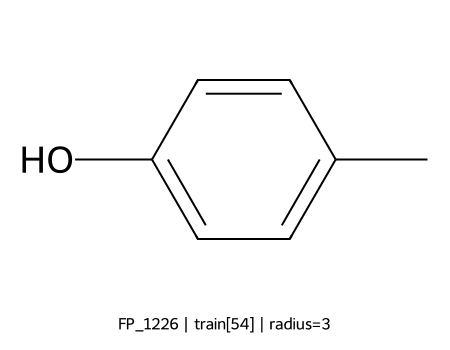

In [125]:
# FP_123を調べる場合は123を指定する。
FP_NUMBER = 1226
FP_DATASET = "both"  # 'train'、'test'、'both'
FP_HIT_INDEX = 0       # 同じFPに複数候補がある場合の表示番号

fp_hits, fp_structure_svg = visualize_fp_structure(
    fp_number=FP_NUMBER,
    hit_index=FP_HIT_INDEX,
    dataset=FP_DATASET,
    output=save_dir / f"FP_{FP_NUMBER}_hit_{FP_HIT_INDEX}.svg",
    show=True,
)

# 新規化合物の予測

In [136]:
df_new = pd.read_csv(
    "/Users/mac_studio_2025/Desktop/compound_list/Antioxidants/FooDB/FooDB_phenol_descriptors.csv", encoding="cp932"
)
df_new = df_new.reset_index(drop=True).copy()

if "iso_SMILES" not in df_new.columns:
    raise KeyError("df_newに'iso_SMILES'列がありません。")
if df_new.empty:
    raise ValueError("df_newに予測対象の化合物がありません。")
if df_new["iso_SMILES"].isna().any():
    missing_rows = df_new.index[df_new["iso_SMILES"].isna()].tolist()
    raise ValueError(f"iso_SMILESが欠損している行があります: {missing_rows}")

# 学習時と同じradius・bit数でMorgan fingerprintを作成する。
n_fp_bits = morgan_fps_data_df.shape[1]
morgan_fps_new = []
bitInfo_list_new = []
mol_list_new = []
invalid_rows = []

for row_index, smiles in enumerate(df_new["iso_SMILES"]):
    try:
        fp_array, bit_info, mol = smiles_to_morgan_fp_with_info(
            smiles, radius=radius, n_bits=n_fp_bits
        )
    except (TypeError, ValueError):
        invalid_rows.append((row_index, smiles))
        continue
    morgan_fps_new.append(fp_array)
    bitInfo_list_new.append(bit_info)
    mol_list_new.append(mol)

if invalid_rows:
    raise ValueError(f"変換できないiso_SMILESがあります: {invalid_rows}")

X_new = np.asarray(morgan_fps_new, dtype=np.float32)
morgan_fps_new_df = pd.DataFrame(
    X_new, columns=[f"FP_{i}" for i in range(n_fp_bits)]
)
if X_new.shape[1] != X_train.shape[1]:
    raise ValueError(
        f"新規化合物と学習データの特徴量数が異なります: "
        f"{X_new.shape[1]} != {X_train.shape[1]}"
    )

# modelにはUSE_PAVAで選択した補正方式がすでに反映されている。
y_pred_new = model.predict(X_new)
y_proba_new = model.predict_proba(X_new)
y_cumulative_proba_new = model.predict_cumulative_proba(X_new)

label_map = {0: "Low", 1: "Middle", 2: "High"}
df_new_predictions = df_new.copy()
df_new_predictions["pava_applied"] = USE_PAVA
df_new_predictions["predicted_class"] = y_pred_new
df_new_predictions["predicted_label"] = pd.Series(y_pred_new).map(label_map)
df_new_predictions["probability_low"] = y_proba_new[:, 0]
df_new_predictions["probability_middle"] = y_proba_new[:, 1]
df_new_predictions["probability_high"] = y_proba_new[:, 2]
df_new_predictions["probability_above_low"] = y_cumulative_proba_new[:, 0]
df_new_predictions["probability_high_cumulative"] = y_cumulative_proba_new[:, 1]
df_new_predictions["maximum_probability"] = np.max(y_proba_new, axis=1)

new_prediction_path = (
    save_dir / f"Ordinal_LightGBM_{file_tag}_new_predictions.csv"
)
df_new_predictions.to_csv(
    new_prediction_path, index=False, encoding="utf-8-sig"
)

print(f"New compound predictions saved: {new_prediction_path}")
print("Prediction shape:", y_pred_new.shape)
display(df_new_predictions)

/var/folders/j1/w6zb7j_92z54t7tbpnfp2lz80000gn/T/ipykernel_13708/1360118257.py:1: DtypeWarning: Columns (0: TPSA, 1: AATS7dv, 2: AATS7d, 3: AATS7s, 4: AATS7Z, 5: AATS7m, 6: AATS7v, 7: AATS7se, 8: AATS7pe, 9: AATS7are, 10: AATS7p, 11: AATS7i, 12: ATSC0c, 13: ATSC1c, 14: ATSC2c, 15: ATSC3c, 16: ATSC4c, 17: ATSC5c, 18: ATSC6c, 19: ATSC7c, 20: ATSC8c, 21: AATSC0c, 22: AATSC1c, 23: AATSC2c, 24: AATSC3c, 25: AATSC4c, 26: AATSC5c, 27: AATSC6c, 28: AATSC7c, 29: AATSC7dv, 30: AATSC7d, 31: AATSC7s, 32: AATSC7Z, 33: AATSC7m, 34: AATSC7v, 35: AATSC7se, 36: AATSC7pe, 37: AATSC7are, 38: AATSC7p, 39: AATSC7i, 40: MATS1c, 41: MATS2c, 42: MATS3c, 43: MATS4c, 44: MATS5c, 45: MATS6c, 46: MATS7c, 47: MATS7dv, 48: MATS7d, 49: MATS7s, 50: MATS7Z, 51: MATS7m, 52: MATS7v, 53: MATS7se, 54: MATS7pe, 55: MATS7are, 56: MATS7p, 57: MATS7i, 58: GATS1c, 59: GATS2c, 60: GATS3c, 61: GATS4c, 62: GATS5c, 63: GATS6c, 64: GATS7c, 65: GATS7dv, 66: GATS7d, 67: GATS7s, 68: GATS7Z, 69: GATS7m, 70: GATS7v, 71: GATS7se, 72: GAT

New compound predictions saved: ../output/multi_classification/double_model_run_003_PAVA/Ordinal_LightGBM_PAVA_new_predictions.csv
Prediction shape: (2536,)


,ID,CID,Name,iso_SMILES,inchikey,E_HOMO_PubChemQC,E_LUMO_PubChemQC,E_state_mean,E_state_max,E_state_min,...,count_cyano,pava_applied,predicted_class,predicted_label,probability_low,probability_middle,probability_high,probability_above_low,probability_high_cumulative,maximum_probability
0,1,19,"2,3-Dihydroxybenzoic acid",O=C(O)c1cccc(O)c1O,GLDQAMYCGOIJDV-UHFFFAOYSA-N,-6.046370,-1.518395,3.480392,11.191262,-1.343472,...,0,True,0,Low,0.800000,0.162963,0.037037,0.200000,0.037037,0.800000
1,2,72,protocatechuate,O=C(O)c1ccc(O)c(O)c1,YQUVCSBJEUQKSH-UHFFFAOYSA-N,-6.144331,-0.848995,3.480392,11.137569,-1.330249,...,0,True,2,High,0.065217,0.351449,0.583333,0.934783,0.583333,0.583333
2,3,86,3-Hydroxyanthranilic acid,Nc1c(O)cccc1C(=O)O,WJXSWCUQABXPFS-UHFFFAOYSA-N,-5.447719,-1.061244,3.481481,11.306818,-1.383056,...,0,True,0,Low,0.571429,0.212355,0.216216,0.428571,0.216216,0.571429
3,4,91,3-(3-Hydroxyphenyl)propanoic acid,O=C(O)CCc1cccc(O)c1,QVWAEZJXDYOKEH-UHFFFAOYSA-N,-6.046370,-0.193201,3.553030,11.283089,-3.448779,...,0,True,1,Middle,0.160000,0.743226,0.096774,0.840000,0.096774,0.743226
4,5,101,3-Hydroxybenzaldehyde,O=Cc1cccc(O)c1,IAVREABSGIHHMO-UHFFFAOYSA-N,-6.375628,-1.697990,3.477778,10.784040,-1.308519,...,0,True,0,Low,0.731707,0.195122,0.073171,0.268293,0.073171,0.731707
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2531,2532,118726653,Moracin K,CC1(C)C=Cc2c(c(O)cc3cc(-c4cc(O)cc(O)c4)oc23)O1,HRYWITBPMMQCBB-UHFFFAOYSA-N,-4.816415,-1.107503,3.197917,8.617272,-3.567221,...,0,True,2,High,0.125000,0.336538,0.538462,0.875000,0.538462,0.538462
2532,2533,118726654,Moracin L,CC1=CCc2c(c(O)cc3cc(-c4cc(O)cc(O)c4)oc23)OC1,FQHZBTIVEUAARU-UHFFFAOYSA-N,-4.906213,-0.955120,3.197917,8.634633,-3.381602,...,0,True,0,Low,0.516484,0.000000,0.483516,0.483516,0.483516,0.516484
2533,2534,118886998,Mulberrofuran E,CC(C)=CCc1c(O)ccc(C(=O)C2C(c3c(O)cc(-c4cc5ccc(...,RQIKMRKKKIMUNB-UHFFFAOYSA-N,-4.898049,-1.025869,3.291165,16.493007,-5.243554,...,0,True,0,Low,0.731707,0.171518,0.096774,0.268293,0.096774,0.731707
2534,2535,121225501,1-Caffeoyl-5-feruloylquinic acid,COc1cc(/C=C/C(=O)O[C@@H]2C[C@@](OC(=O)/C=C/c3c...,DJXURFUTIYZESV-BQYLRUKMSA-N,-5.782419,-2.000037,3.483073,13.687007,-5.081372,...,0,True,2,High,0.146209,0.253791,0.600000,0.853791,0.600000,0.600000
